## Data Mining

### Obiettivo

Utilizzare algoritmi di classificazione di Data Mining per analizzare un dataset reale mediante Python.

Il dataset Credit (credit.xlsx) raccoglie informazioni relative alle richieste di prestito presentate a una banca tedesca. Ogni record del dataset corrisponde a un diverso richiedente e contiene un insieme di caratteristiche personali, finanziarie e relative al prestito (ad esempio, l'età del richiedente, il saldo del conto corrente e l'importo richiesto). A seconda che il richiedente si sia dimostrato un debitore affidabile o meno, a ogni record è inoltre associata un'etichetta di classe (class label) che identifica il rischio di credito come "good" oppure "bad". Questo attributo, che verrà utilizzato come attributo di classe per tutto l'homework, è riportato come ultimo attributo di ciascun record.

Il dataset deriva dal dataset Statlog (German Credit Data) della UCI Machine Learning Repository [1]: è stato selezionato un sottoinsieme degli attributi originali, i codici categorici sono stati sostituiti con etichette leggibili e gli attributi numerici sono stati discretizzati in intervalli.

L'elenco completo degli attributi del dataset è riportato di seguito.

1. ID – identificativo della richiesta di prestito

2. Age – età del richiedente (anni)

3. Checking-status – saldo del conto corrente esistente (DM)

4. Duration – durata del prestito (mesi)

5. Credit-history – storico dei rimborsi dei prestiti precedenti

6. Purpose – finalità del prestito (ad esempio, acquisto di una nuova automobile, istruzione, attività commerciale)

7. Credit-amount – importo richiesto (DM)

8. Savings – saldo del conto di risparmio (DM)

9. Employment-since – anni di impiego presso l'attuale datore di lavoro

10. Housing – situazione abitativa (affitto, proprietà, alloggio gratuito)

11. class (attributo di classe) – rischio di credito good / bad

### Contesto

L'ufficio di gestione del rischio della banca intende prevedere se un nuovo richiedente sarà un debitore affidabile o meno, sulla base delle sue caratteristiche personali, finanziarie e relative al prestito, al fine di supportare la decisione di concessione del finanziamento.

A questo scopo, gli analisti utilizzano tre diversi algoritmi di classificazione: un albero decisionale (Decision Tree), un classificatore bayesiano (Naïve Bayes) e un classificatore basato sulla distanza (K-Nearest Neighbors, K-NN). Il dataset Credit viene utilizzato per addestrare i classificatori e valutarne le prestazioni. Per rendere riproducibili i risultati, impostare random_state=42 ovunque il parametro sia disponibile (Decision Tree, suddivisione dei dati per la crossvalidation).

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB, CategoricalNB

In [6]:
# Caricamneto del dataset
df = pd.read_excel('./Datasets/credit.xlsx')
df.head()

,ID,age,checking-status,duration,credit-history,purpose,credit-amount,savings,employment-since,housing,Class
0,APP0001,60-75,<0,04-12,critical,radio-tv,00000-01999,unknown,07+,own,good
1,APP0002,19-29,0-199,37-72,existing-paid,radio-tv,04000-05999,0000-0099,01-03,own,bad
2,APP0003,40-49,no-account,04-12,critical,education,02000-03999,0000-0099,04-06,own,good
3,APP0004,40-49,<0,37-72,existing-paid,furniture,06000-09999,0000-0099,04-06,free,good
4,APP0005,50-59,<0,13-24,past-delays,new-car,04000-05999,0000-0099,01-03,free,bad


In [12]:
# Pulizia dati
print("Record iniziali:", len(df))
df = df.drop_duplicates()
print("Record senza duplicati:", len(df))

Record iniziali: 1000
Record senza duplicati: 1000


In [15]:
# Separazione di X e y (rimuoviamo ID perché non è una feature predittiva)
X = df.drop(columns=['ID', 'Class'])
y = df['Class']

In [16]:
# Verifica del bilanciamento delle classi
print("Distribuzione delle classi:\n", y.value_counts())

Distribuzione delle classi:
 Class
good    700
bad     300
Name: count, dtype: int64


In [18]:
# Codifica delle feature categoriche con LabelEncoder salvando gli encoder in un dizionario
encoders = {}
X_encoded = X.copy()

for col in X_encoded.select_dtypes(include=['object', 'string']).columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    encoders[col] = le

In [19]:
# Aggiornamento X con le feature codificate
X = X_encoded
X.head()

,age,checking-status,duration,credit-history,purpose,credit-amount,savings,employment-since,housing
0,4,1,0,1,6,0,4,3,1
1,0,0,3,2,6,2,0,1,1
2,2,3,0,1,2,1,0,2,1
3,2,1,3,2,3,3,0,2,0
4,3,1,1,4,4,2,0,1,0


### Domande

1. Addestrare un albero decisionale (Decision Tree) sull'intero dataset, utilizzando il criterio di suddivisione entropy e impostando la profondità massima a 4, mantenendo i valori predefiniti per tutti gli altri parametri.

    (a) Quale attributo risulta essere il più discriminante per la predizione della classe? Quali attributi vengono utilizzati al secondo livello dell'albero?

    (b) Qual è l'altezza dell'albero decisionale generato e quante foglie possiede?

    (c) Individuare una partizione pura nell'albero decisionale, allegare l'immagine dell'albero prodotta dal codice, evidenziando la foglia pura individuata, e scrivere la regola decisionale ( IF … THEN class = … ) che conduce a tale foglia.

In [20]:
# Decision Tree Classifier
dt = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

In [21]:
# Addestramento del Decision Tree 
dt.fit(X, y)

DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

In [24]:
# Compute the accuracy on the training set
y_pred = dt.predict(X)
train_acc = accuracy_score(y, y_pred)
print(f"Training accuracy: {train_acc:.4f}")

Training accuracy: 0.7640


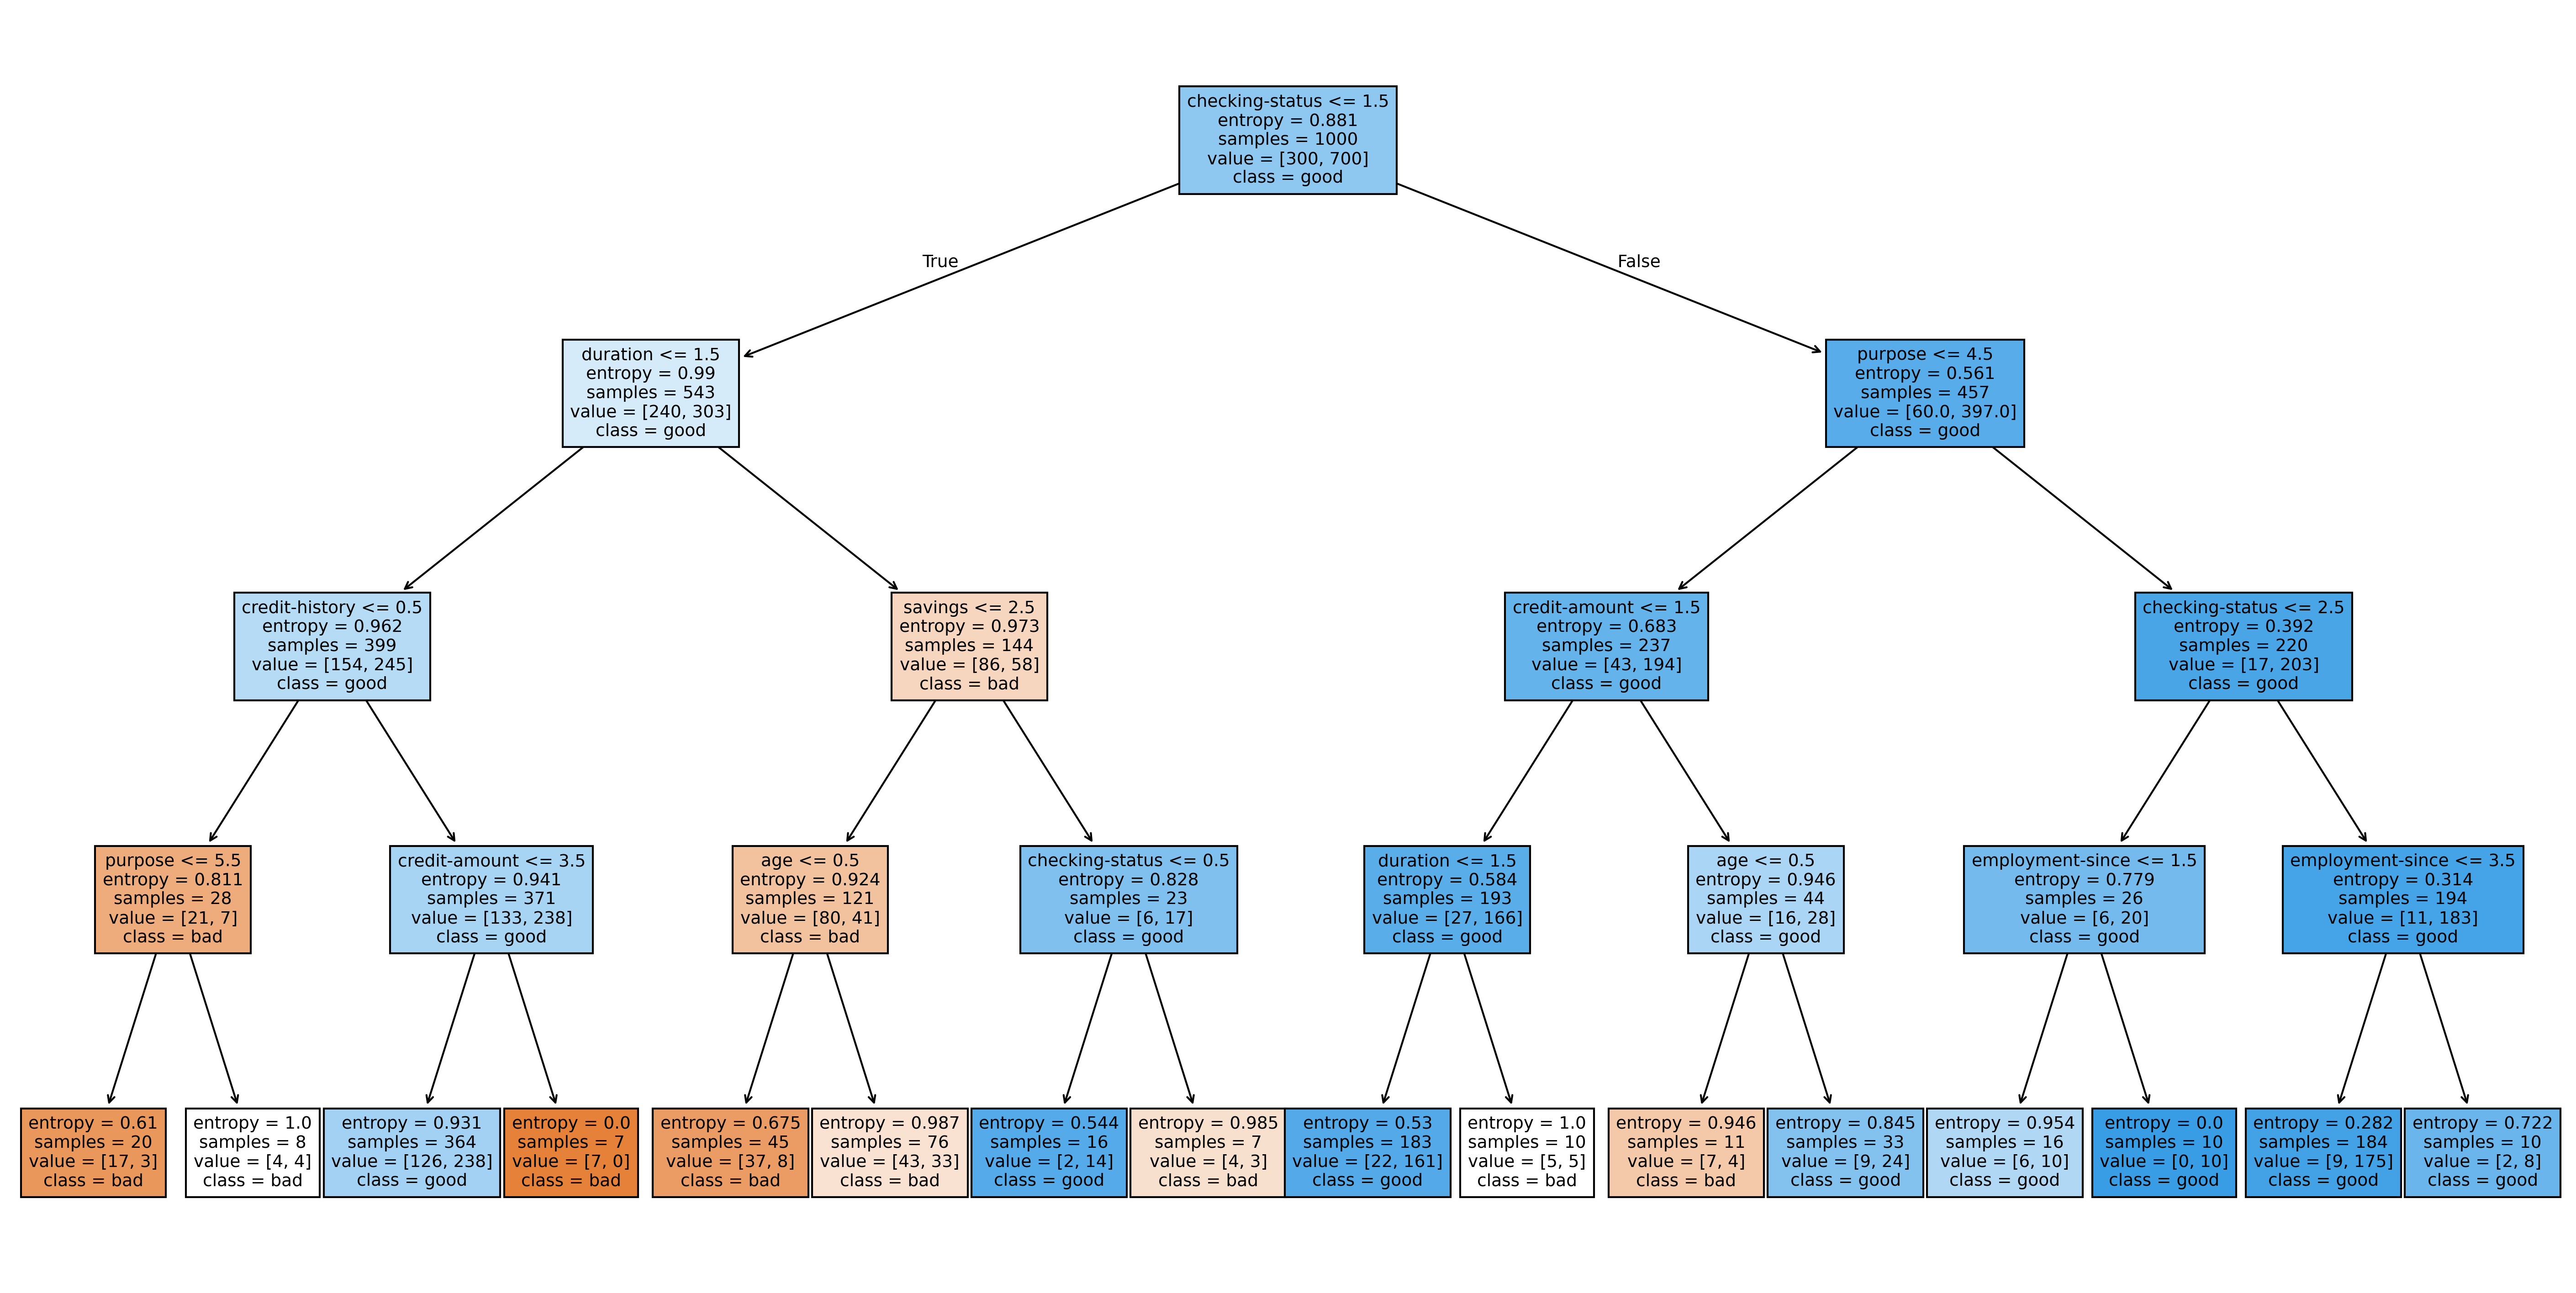

Profondità dell'albero: 4
Numero di foglie: 16


In [35]:
fig, ax = plt.subplots(figsize=(24, 12), dpi=300)
plot_tree(
    dt,
    feature_names=list(X.columns),
    class_names=[str(c) for c in dt.classes_],
    filled=True,
    fontsize=9,
)
plt.savefig("./figs/DecisionTree.png")
plt.show()

# Decision tree depth and number of leaves
print(f"Profondità dell'albero: {dt.get_depth()}")
print(f"Numero di foglie: {dt.get_n_leaves()}")

In [29]:
print(export_text(dt, feature_names=list(X.columns), class_names=list(dt.classes_), show_weights=True))

|--- checking-status <= 1.50
|   |--- duration <= 1.50
|   |   |--- credit-history <= 0.50
|   |   |   |--- purpose <= 5.50
|   |   |   |   |--- weights: [17.00, 3.00] class: bad
|   |   |   |--- purpose >  5.50
|   |   |   |   |--- weights: [4.00, 4.00] class: bad
|   |   |--- credit-history >  0.50
|   |   |   |--- credit-amount <= 3.50
|   |   |   |   |--- weights: [126.00, 238.00] class: good
|   |   |   |--- credit-amount >  3.50
|   |   |   |   |--- weights: [7.00, 0.00] class: bad
|   |--- duration >  1.50
|   |   |--- savings <= 2.50
|   |   |   |--- age <= 0.50
|   |   |   |   |--- weights: [37.00, 8.00] class: bad
|   |   |   |--- age >  0.50
|   |   |   |   |--- weights: [43.00, 33.00] class: bad
|   |   |--- savings >  2.50
|   |   |   |--- checking-status <= 0.50
|   |   |   |   |--- weights: [2.00, 14.00] class: good
|   |   |   |--- checking-status >  0.50
|   |   |   |   |--- weights: [4.00, 3.00] class: bad
|--- checking-status >  1.50
|   |--- purpose <= 4.50
|   |   

a) L'attributo 'checking-status' risulta il più discriminante (minimizza l'information gain).  Gli attributi del secondo livello sono 'purpose' e 'duration'

b) Altezza: 4 , Foglie: 16

c) Abbiamo una foglia pura sul ramo sinistro. La regola: IF checking-status <= 1.5  AND duration <= 1.5 AND credit-history > 0.5 AND credit-amount > 3.5 THEN class = bad

2. Analizzare l'impatto dei parametri criterio di suddivisione (Gini vs entropy), profondità massima, numero minimo di campioni per foglia, numero massimo di nodi foglia e riduzione minima dell'impurità sulle caratteristiche del modello di albero decisionale addestrato sull'intero dataset (mantenere i valori predefiniti per tutti gli altri parametri). Per ogni configurazione, riportare anche l'accuracy ottenuta sul training set. 

In [37]:
configs = [
    # Default (Gini, senza limiti)
    {"criterion": "gini"},
    # 1. Criterio di suddivisione: Entropy vs Gini
    {"criterion": "entropy"},
    # 2. Profondità massima (max_depth)
    {"max_depth": 2},
    {"max_depth": 4},
    {"max_depth": 6},
    {"max_depth": 10},
    # 3. Numero minimo di campioni per foglia (min_samples_leaf)
    {"min_samples_leaf": 5},
    {"min_samples_leaf": 15},
    {"min_samples_leaf": 30},
    {"min_samples_leaf": 50},
    # 4. Numero massimo di nodi foglia (max_leaf_nodes)
    {"max_leaf_nodes": 5},
    {"max_leaf_nodes": 10},
    {"max_leaf_nodes": 20},
    {"max_leaf_nodes": 50},
    # 5. Riduzione minima dell'impurità (min_impurity_decrease)
    {"min_impurity_decrease": 0.005},
    {"min_impurity_decrease": 0.01},
    {"min_impurity_decrease": 0.02},
    {"min_impurity_decrease": 0.05},
]

results_q2 = []

for cfg in configs:
    clf = DecisionTreeClassifier(random_state=42, **cfg)
    clf.fit(X, y)
    train_acc = accuracy_score(y, clf.predict(X))
    results_q2.append({
        "Configurazione": str(cfg),
        "Profondità": clf.get_depth(),
        "Foglie": clf.get_n_leaves(),
        "Train Accuracy": round(train_acc, 4)
    })

df_q2 = pd.DataFrame(results_q2)
df_q2

,Configurazione,Profondità,Foglie,Train Accuracy
0,{'criterion': 'gini'},23,328,0.979
1,{'criterion': 'entropy'},24,327,0.979
2,{'max_depth': 2},2,4,0.728
3,{'max_depth': 4},4,16,0.764
4,{'max_depth': 6},6,49,0.795
5,{'max_depth': 10},10,154,0.893
6,{'min_samples_leaf': 5},16,124,0.832
7,{'min_samples_leaf': 15},9,47,0.785
8,{'min_samples_leaf': 30},7,24,0.748
9,{'min_samples_leaf': 50},6,14,0.735


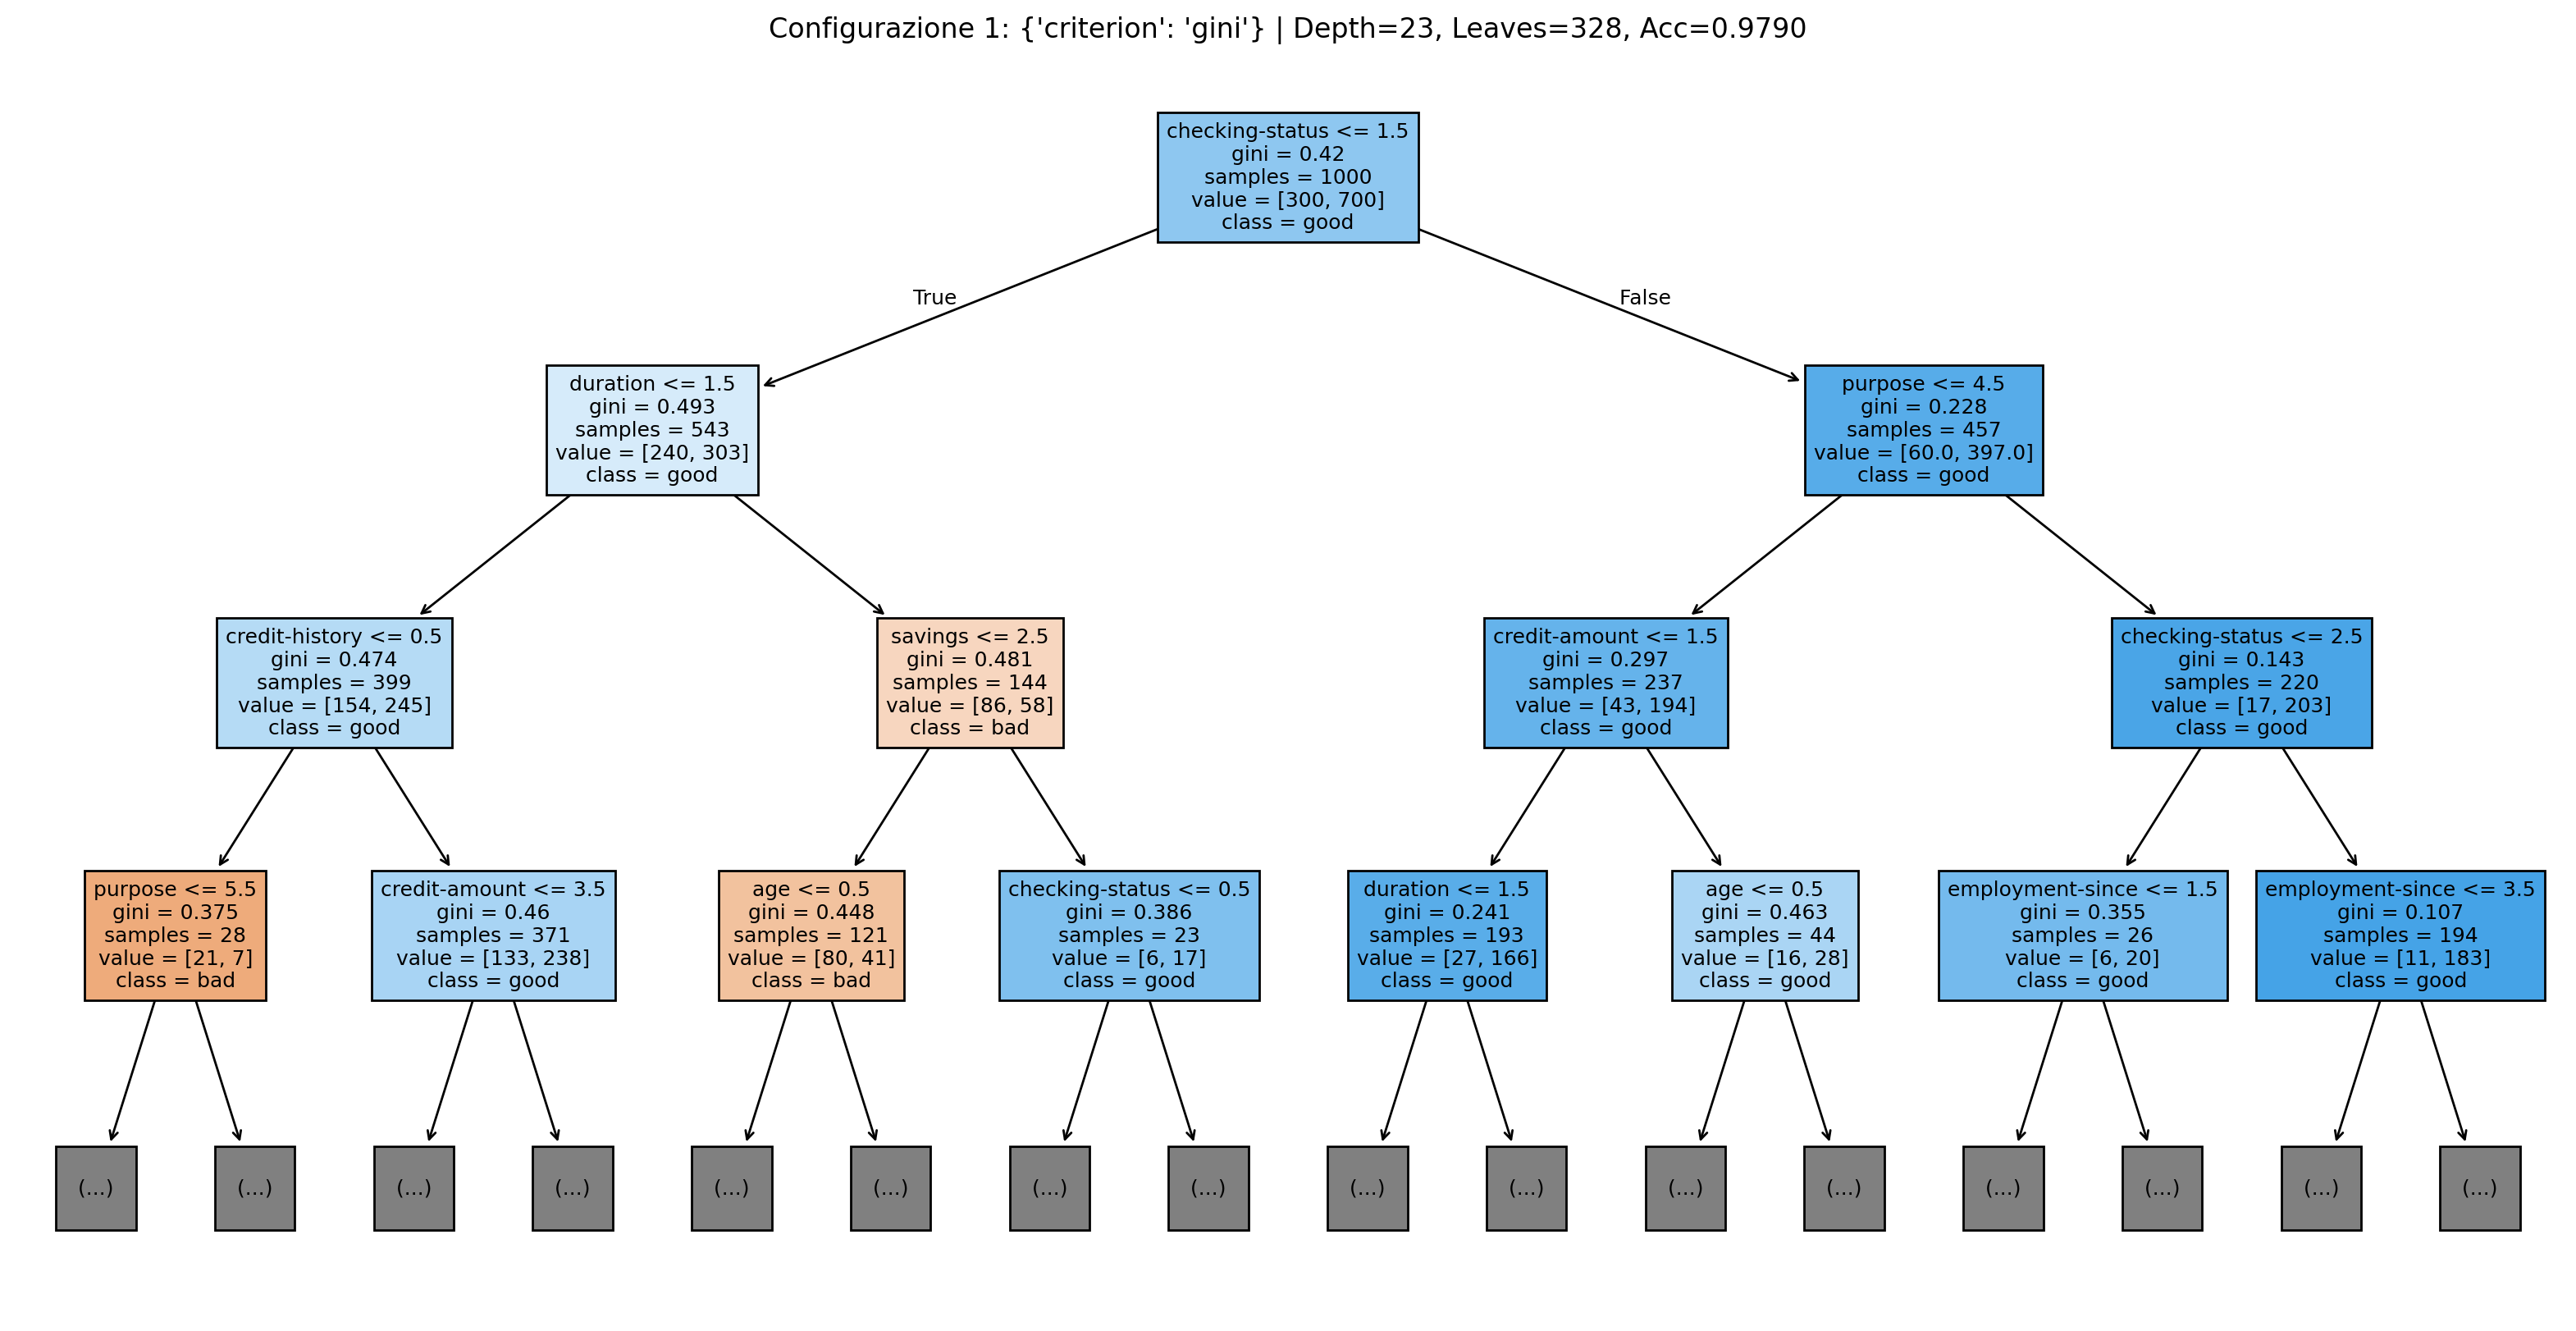

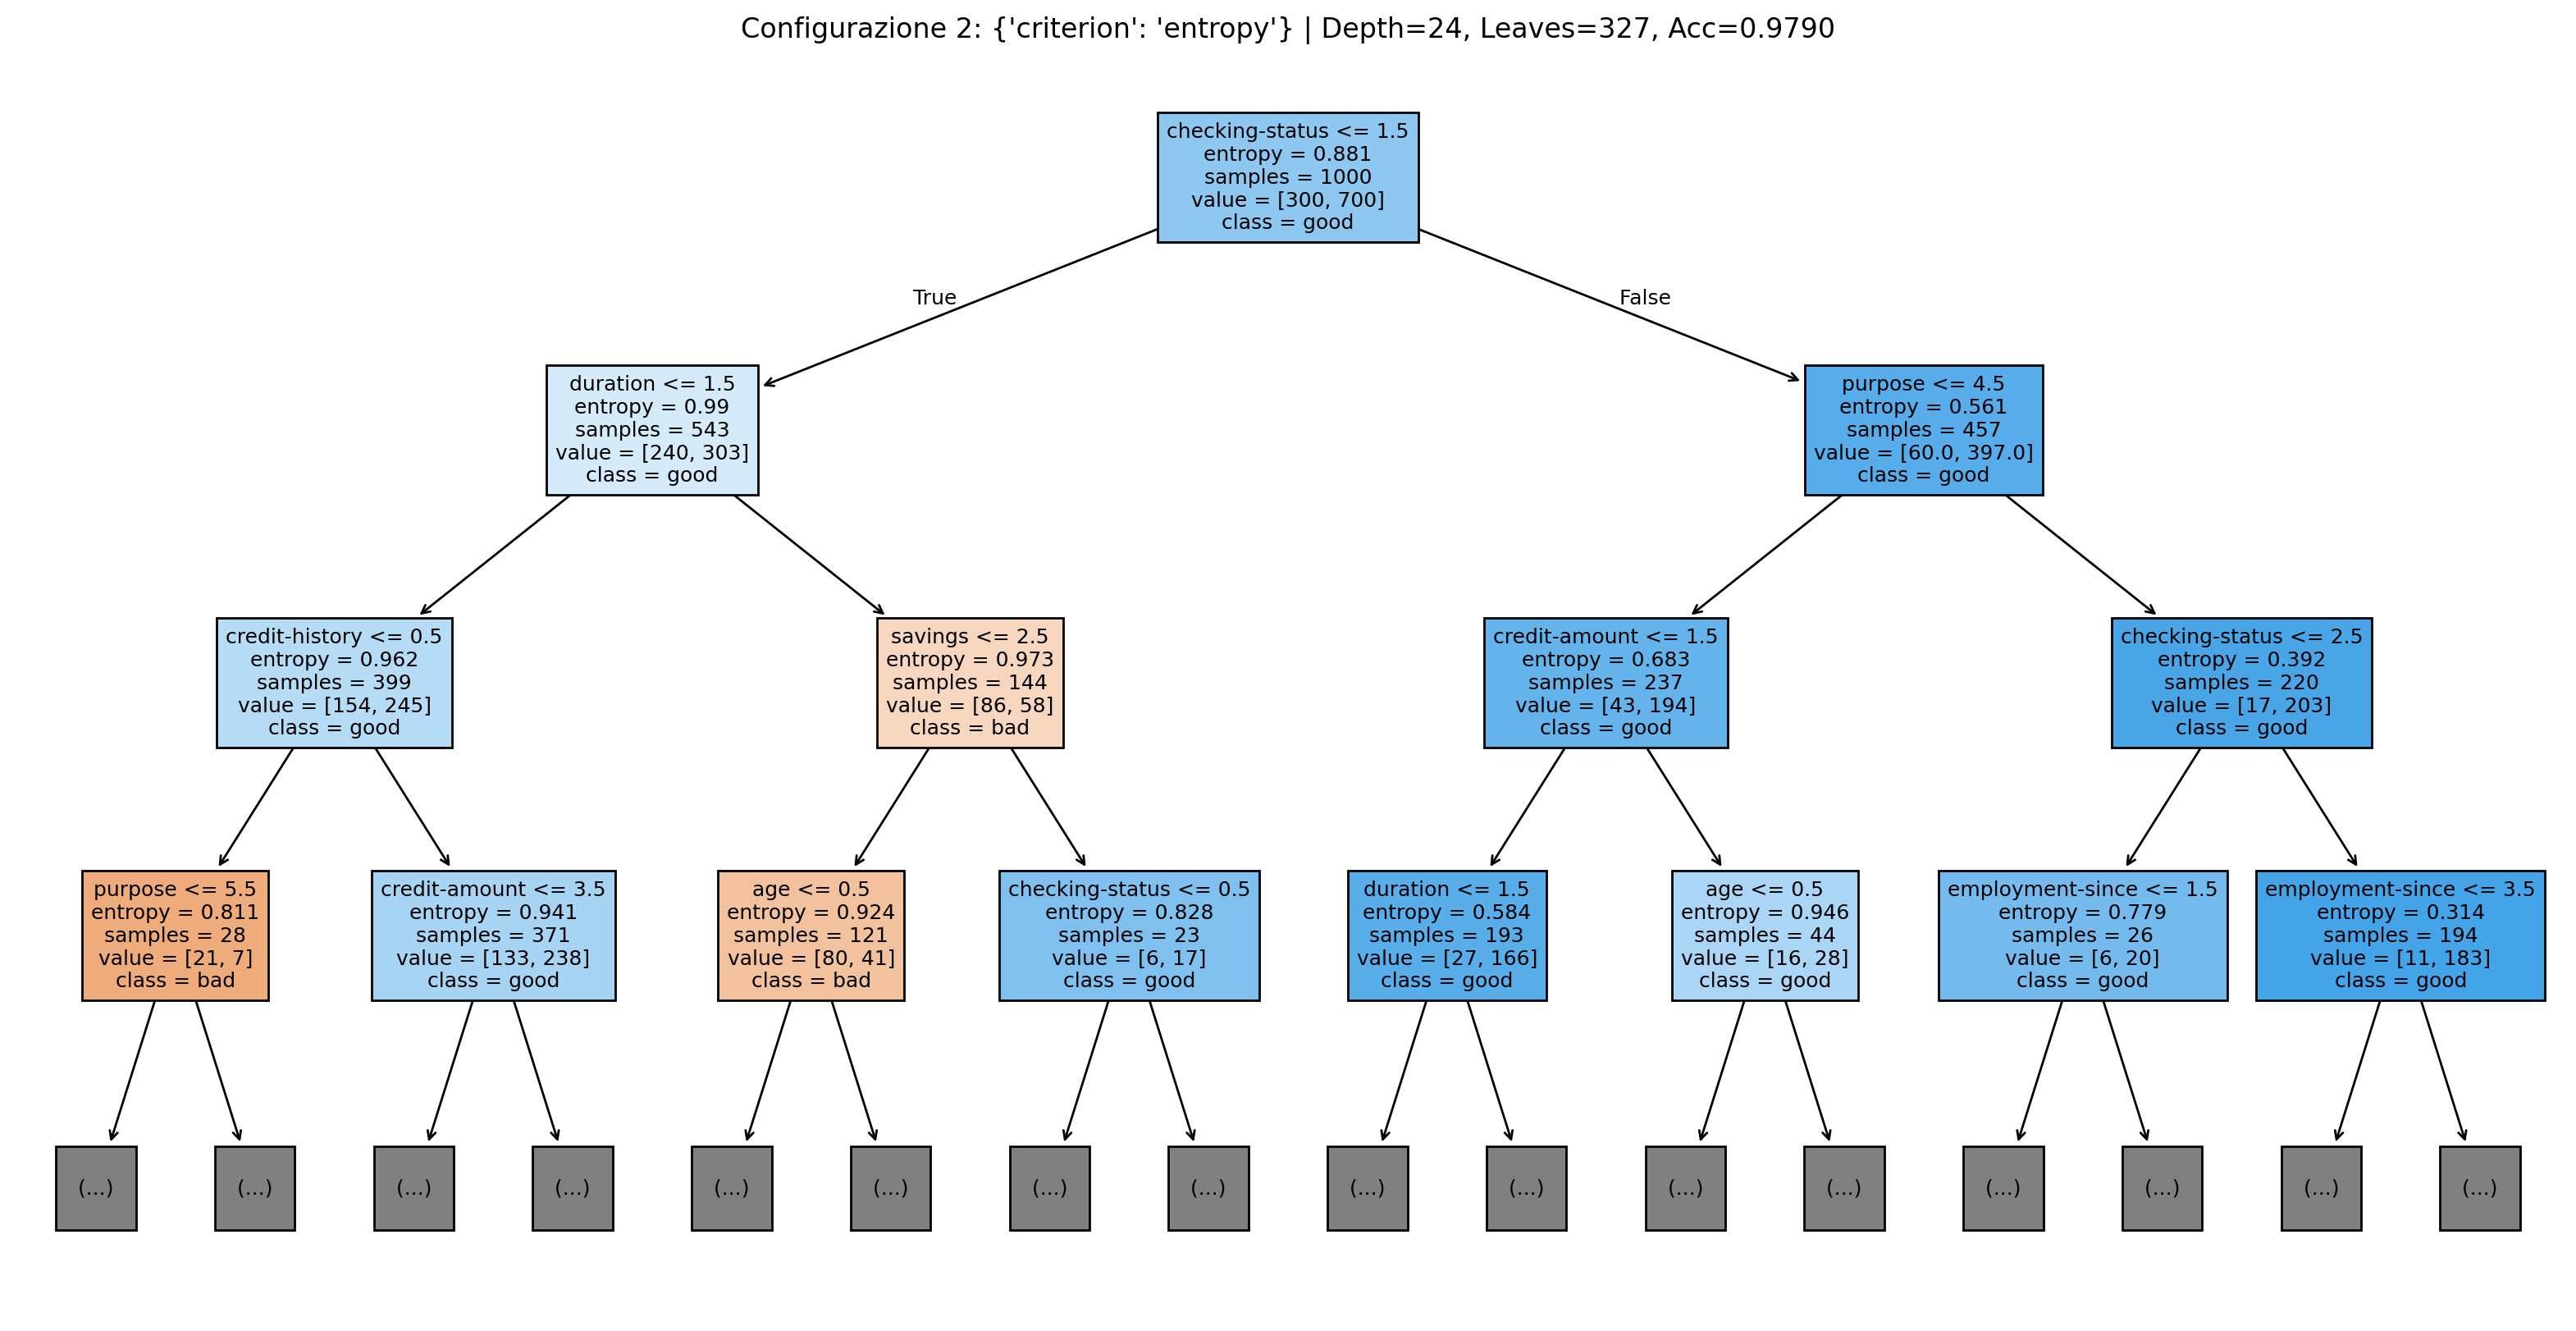

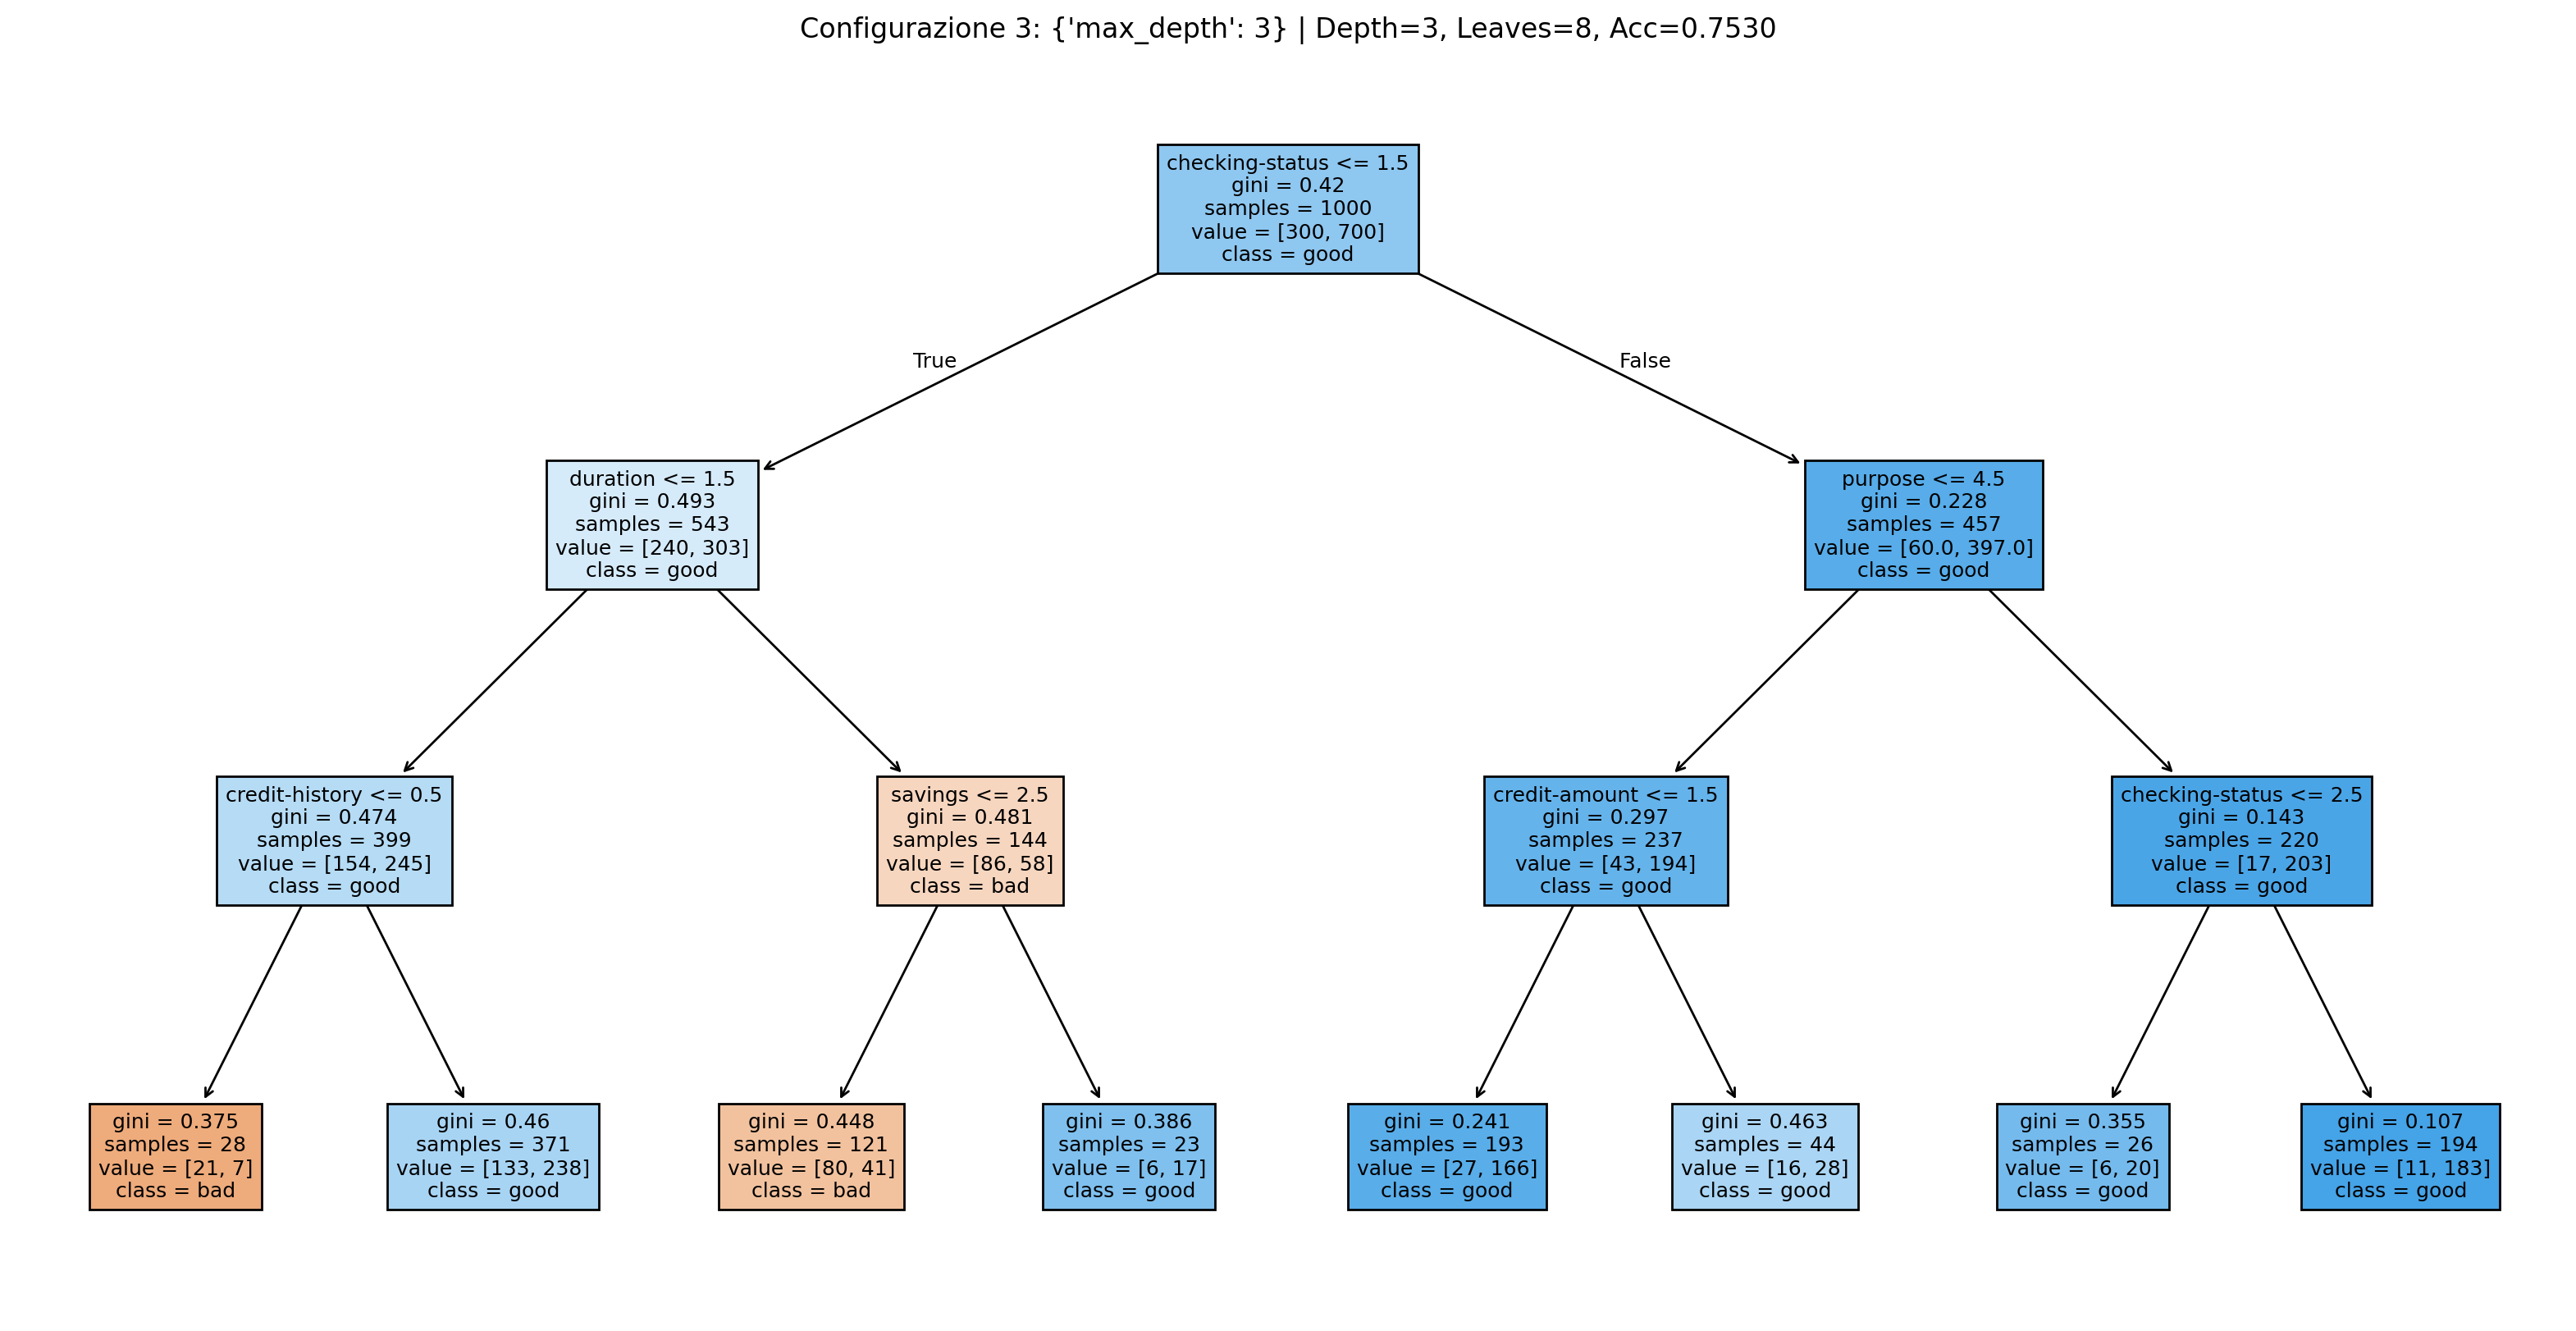

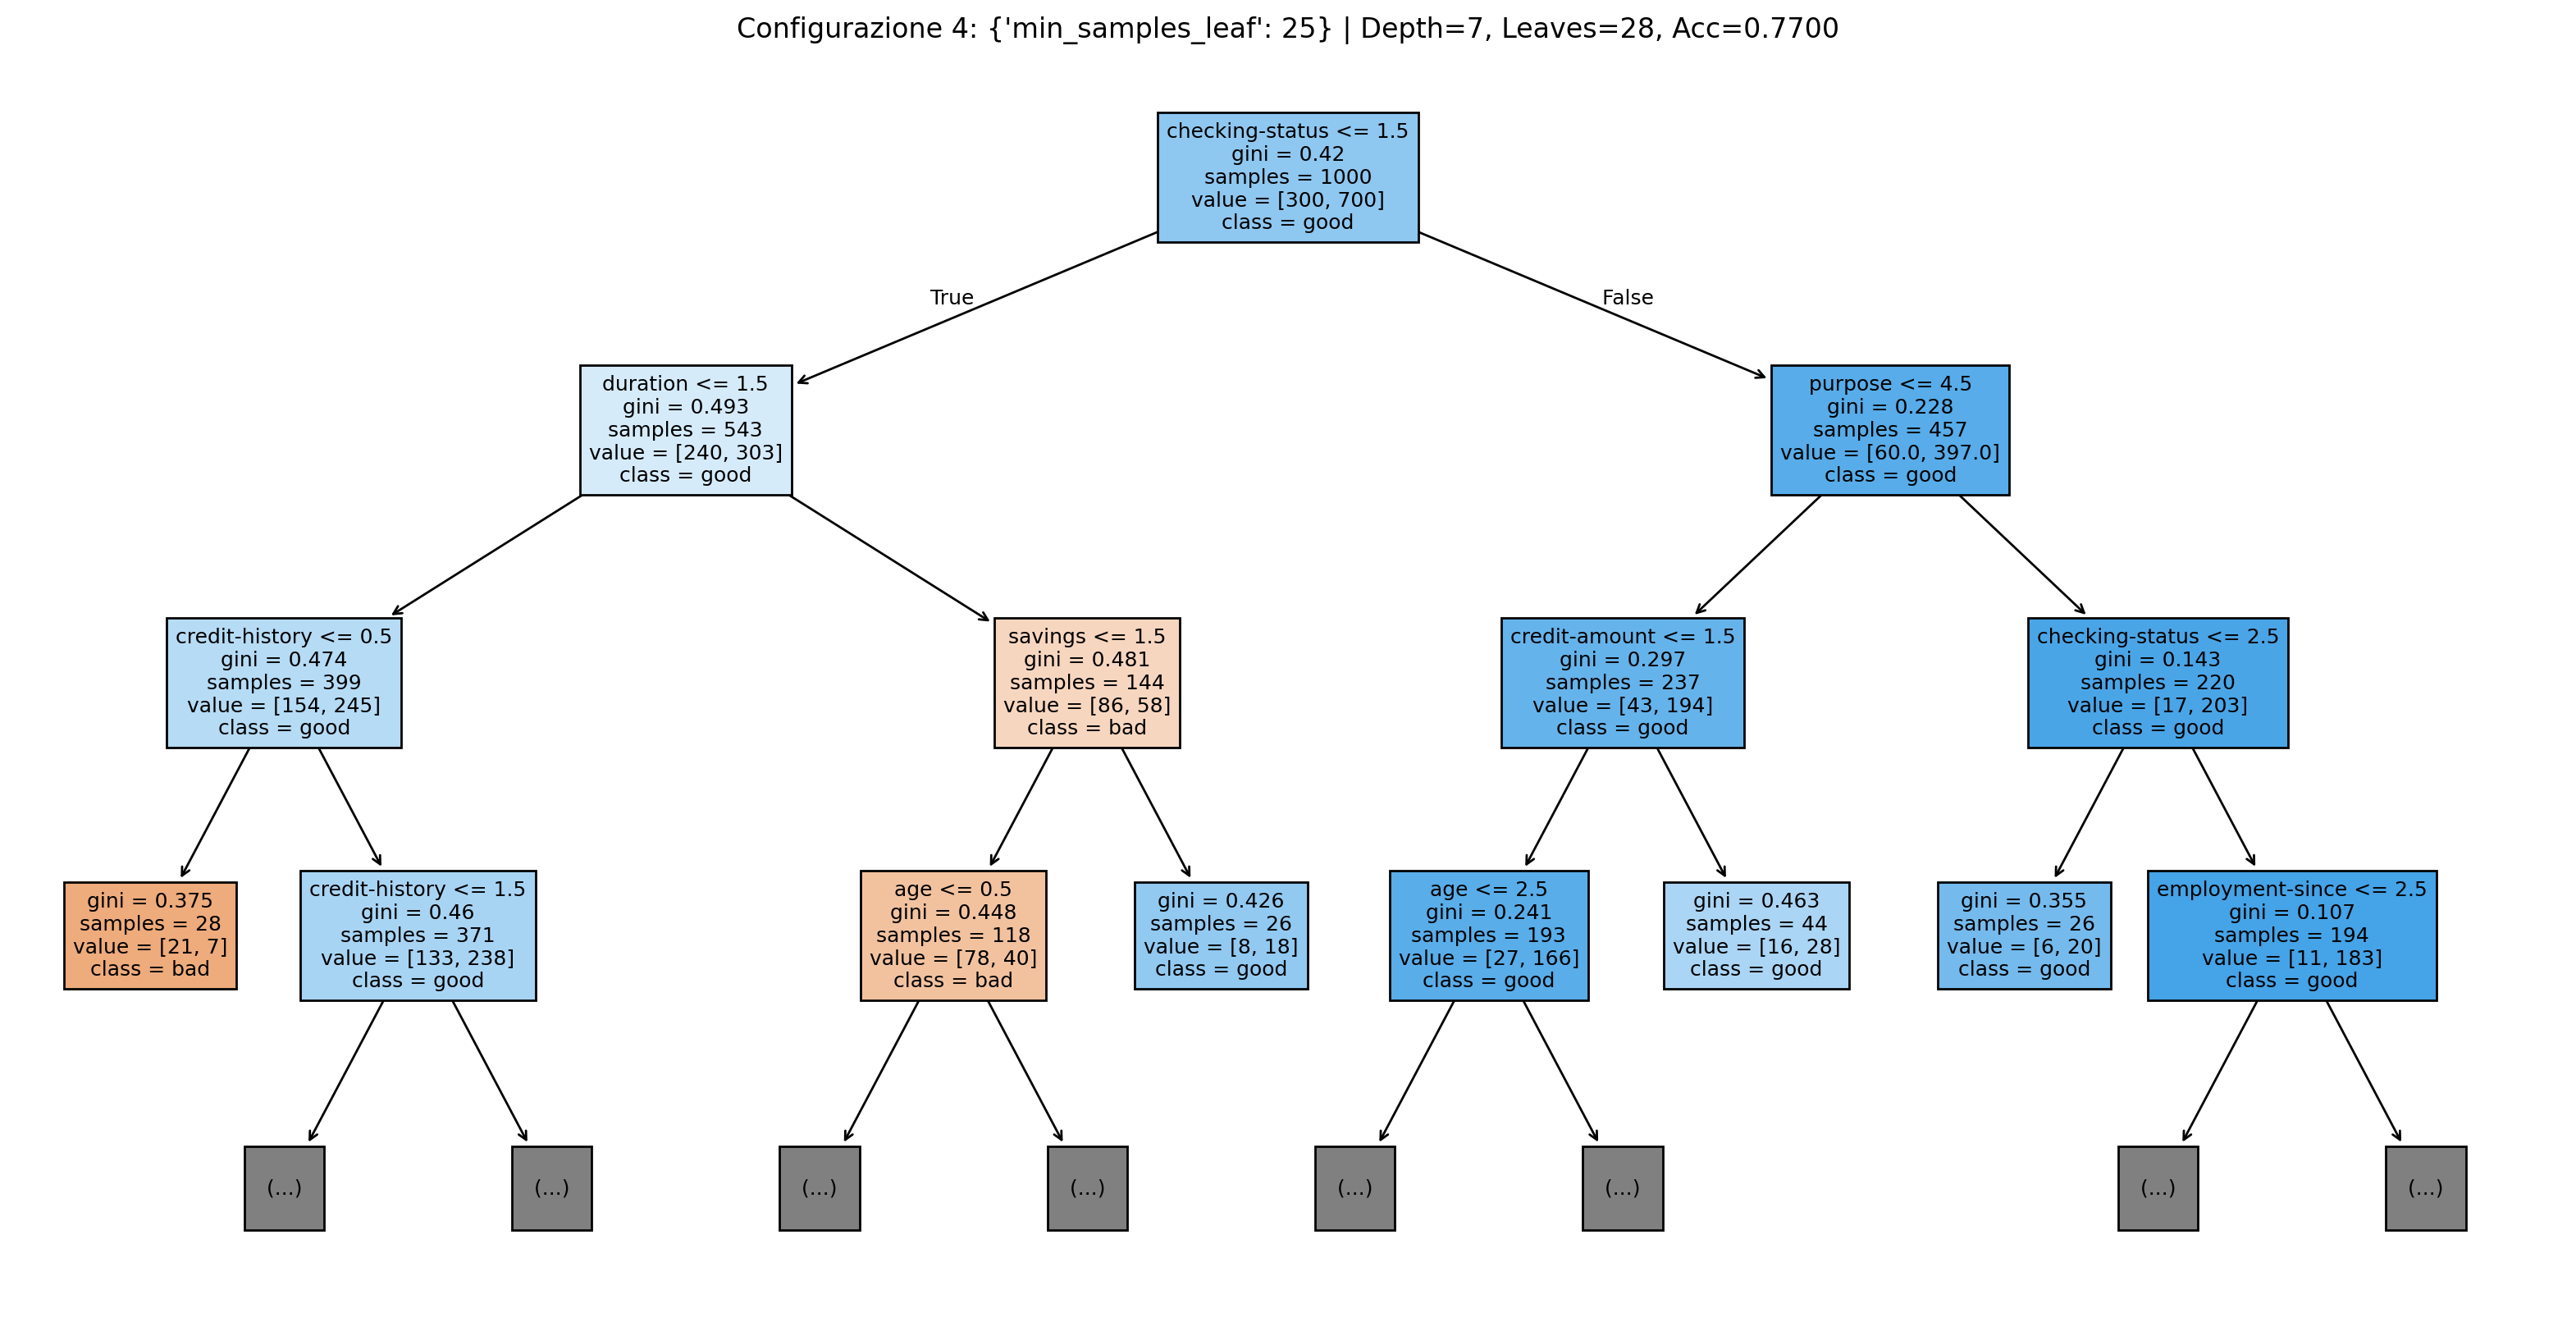

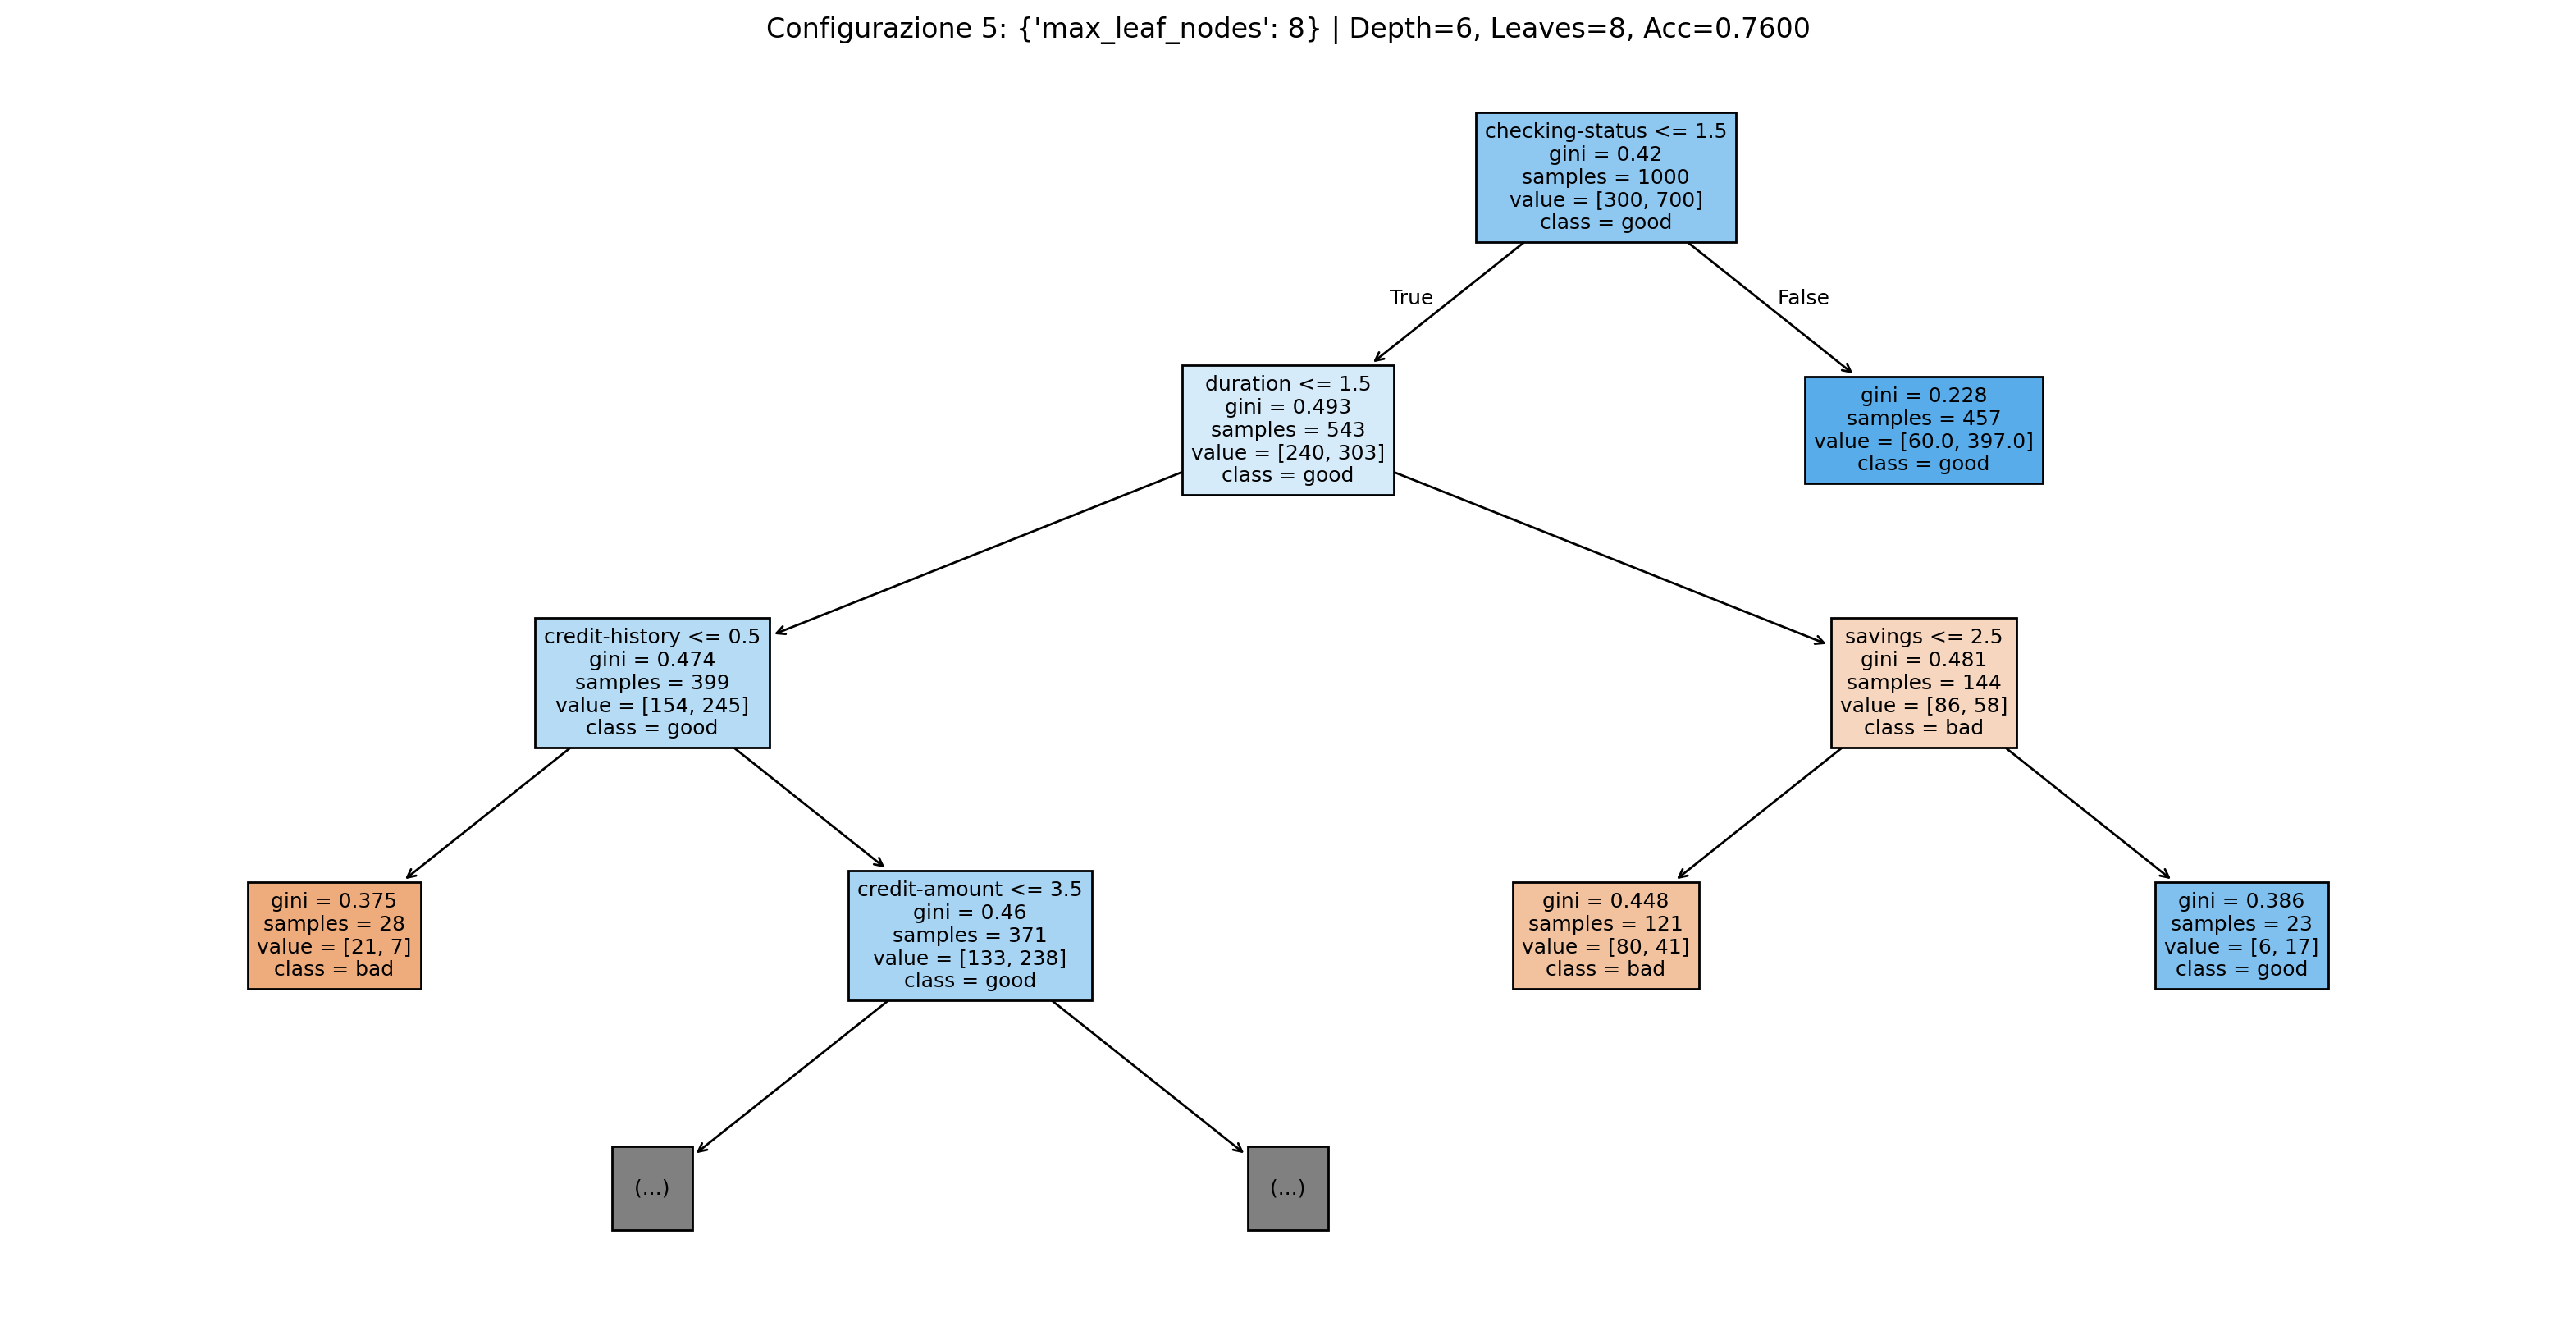

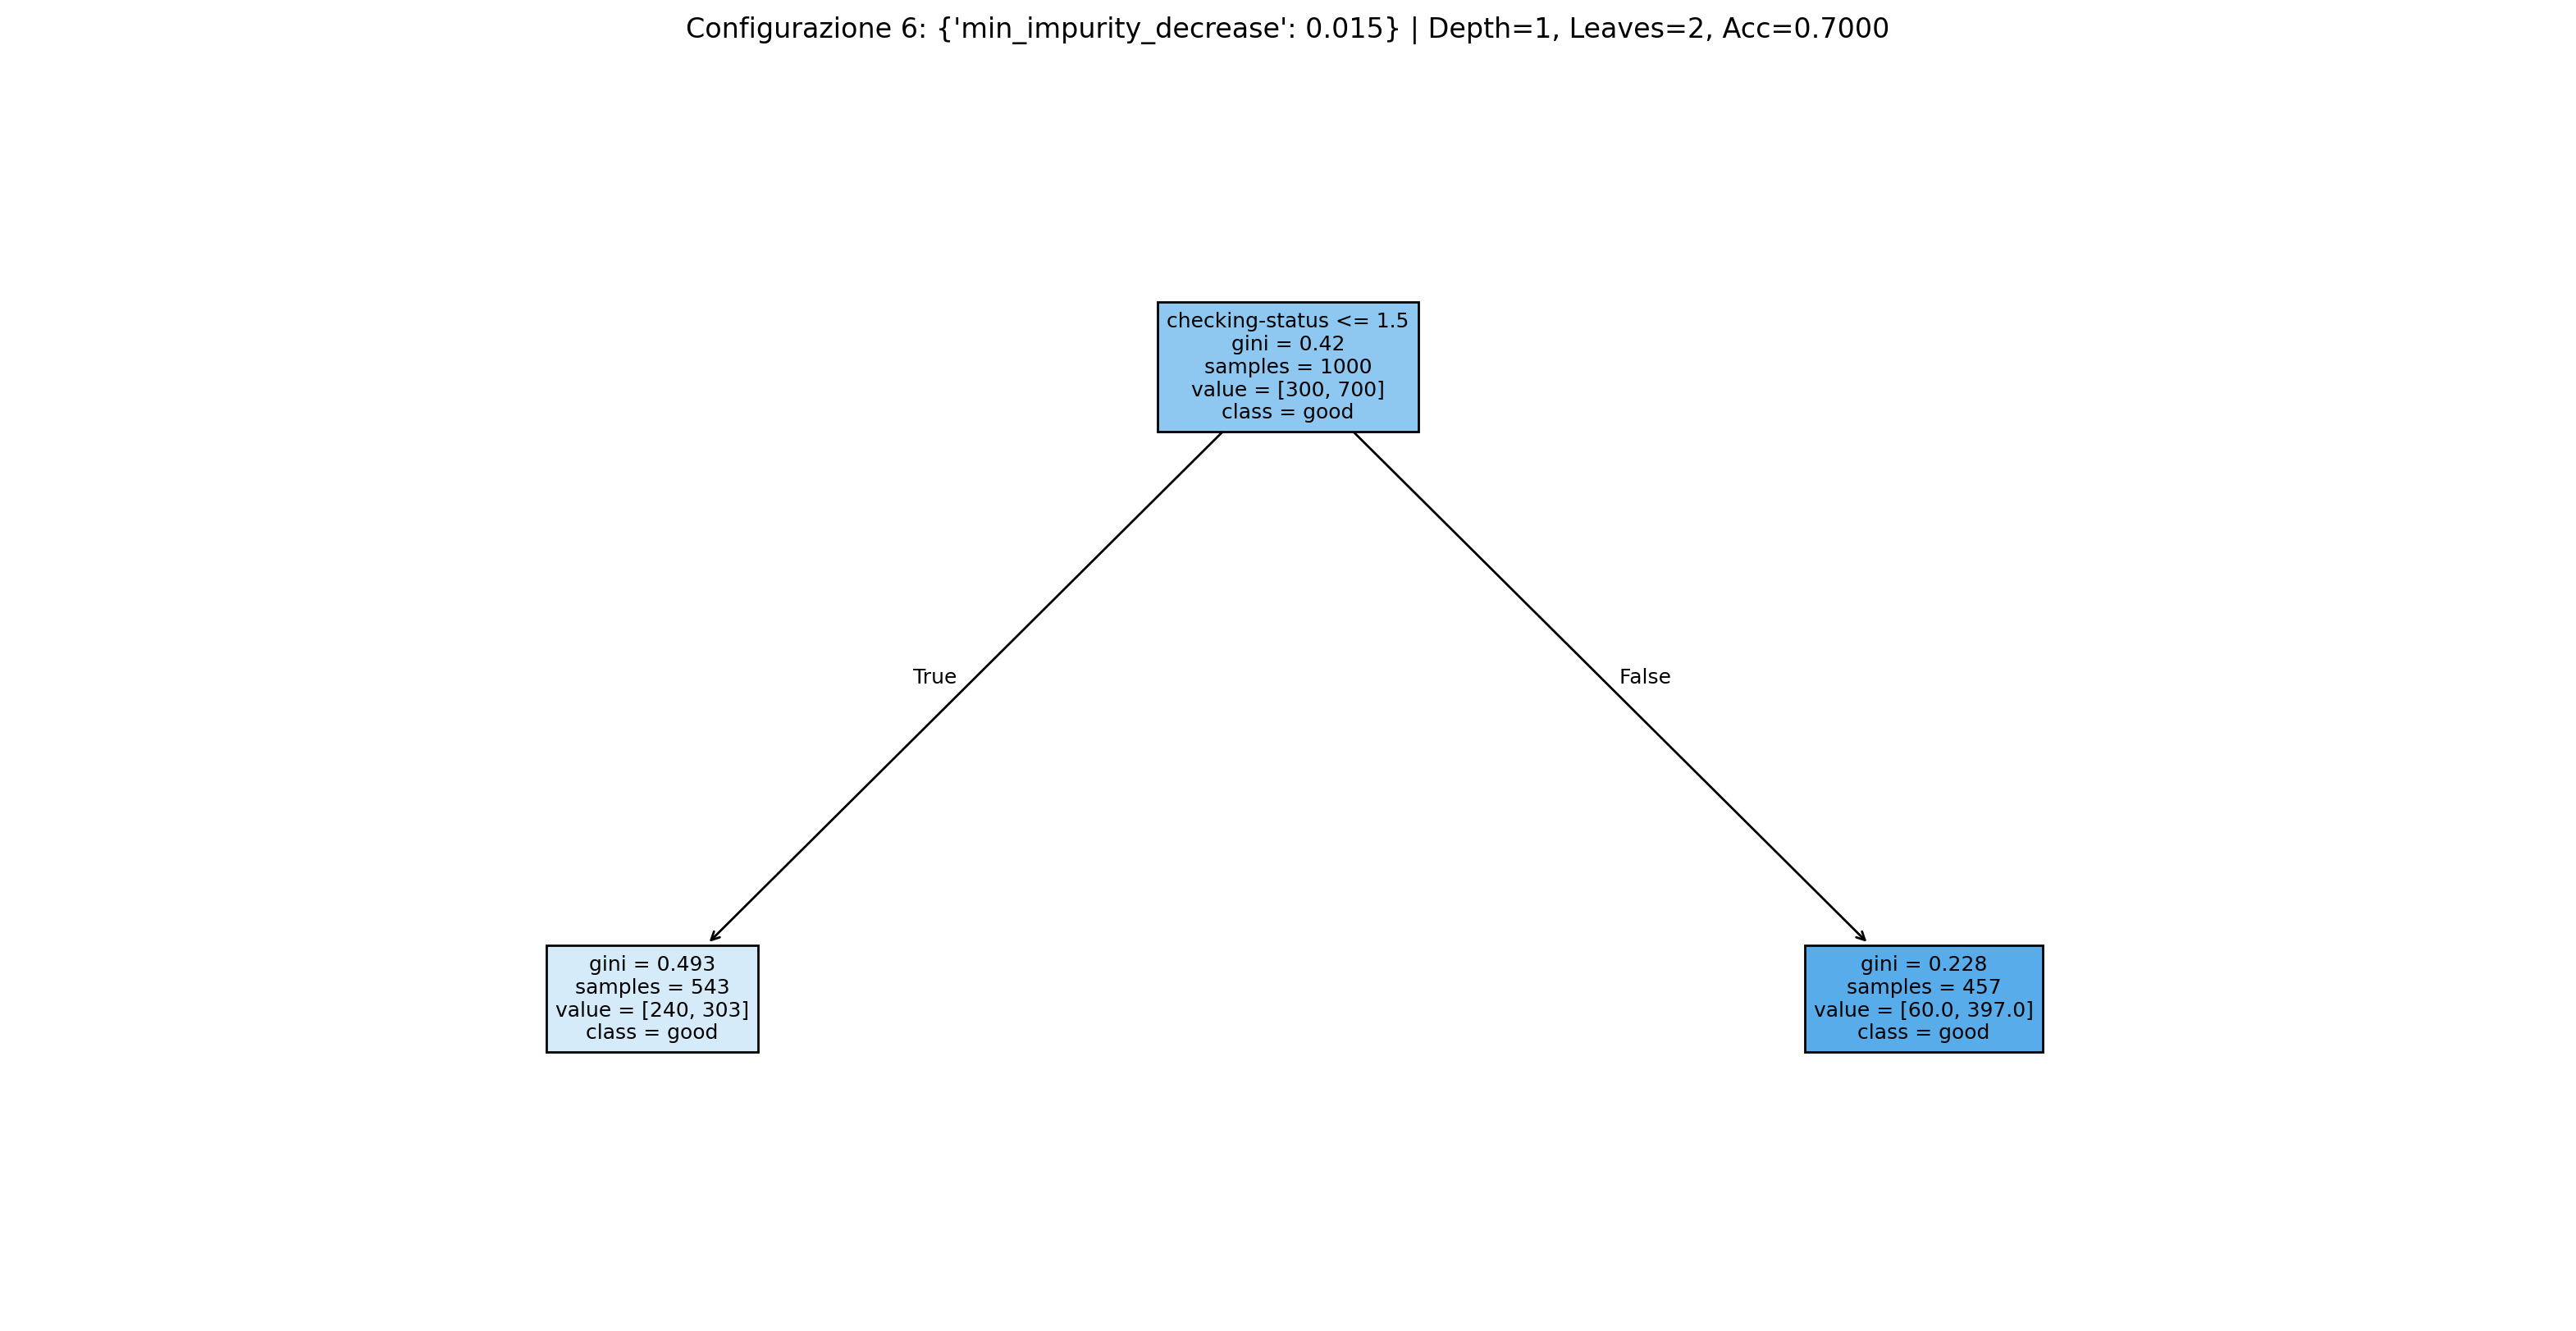

In [40]:
plot_configs = [
    {"criterion": "gini"},
    {"criterion": "entropy"},
    {"max_depth": 3},
    {"min_samples_leaf": 25},
    {"max_leaf_nodes": 8},
    {"min_impurity_decrease": 0.015},
]

for i, cfg in enumerate(plot_configs, 1):
    clf = DecisionTreeClassifier(random_state=42, **cfg)
    clf.fit(X, y)
    
    fig, ax = plt.subplots(figsize=(20, 10), dpi=200)
    plot_tree(
        clf,
        feature_names=list(X.columns),
        class_names=[str(c) for c in clf.classes_],
        filled=True,
        max_depth=3,
        fontsize=9,
    )
    ax.set_title(f"Configurazione {i}: {cfg} | Depth={clf.get_depth()}, Leaves={clf.get_n_leaves()}, Acc={accuracy_score(y, clf.predict(X)):.4f}")
    plt.savefig(f"./figs/tree_{i}.png", bbox_inches="tight")
    plt.show()

Senza vincoli sui parametri, l'albero cresce finché non riesce a separare quasi tutti i record del dataset, raggiungendo un'accuracy sul training set dello 0.979 (overfitting).

- Criterio di suddivisione : i due criteri producono alberi molto simili (uguali fin a livello 3) per dimensione e prestazioni (rispettivamente profondità 23 con 328 foglie e profondità 24 con 327 foglie), mantenendo entrambi una training accuracy di 0.979.

- Profondità massima : limita direttamente l'altezza dell'albero e il numero massimo di foglie (2^max_depth). Riducendo il valore da 10 a 6, 4 e 2, le foglie scendono da 154 a 49, 16 e 4, mentre la training accuracy scende progressivamente da 0.893 a 0.795, 0.764 e 0.728.

- Numero minimo di campioni per foglia : impedisce la creazione di partizioni troppo piccole e specifiche. Aumentando la soglia da 5 a 15, 30 e 50, l'altezza si riduce da 16 a 9, 7 e 6, le foglie scendono da 124 a 47, 24 e 14 e la training accuracy diminuisce da 0.832 a 0.785, 0.748 e 0.735.

- Numero massimo di nodi foglia : passando da 5 a 10, 20 e 50 foglie, la profondità aumenta da 3 a 7, 10 e 14 e la training accuracy sale gradualmente da 0.753 a 0.760, 0.782 e 0.836.

- Riduzione minima dell'impurità : esegue uno split solo se la riduzione dell'impurità supera la soglia fissata. Con 0.005 l'albero si ferma a profondità 4 con 6 foglie e accuracy 0.760; già a partire da 0.01 e 0.02 resta un solo split profondità 1, 2 foglie e accuracy 0.700 fino ad arrivare a un singolo nodo radice con 0.05 profondità 0, 1 foglia e accuracy 0.700.

3. Eseguendo una Stratified Cross-Validation a 5 fold, quale impatto hanno i parametri analizzati nella Domanda 2 sull'accuracy media e sul macro F1-score ottenuti dall'albero decisionale? Allegare almeno 5 immagini delle matrici di confusione prodotte dal proprio codice (ad esempio, mediante ConfusionMatrixDisplay) per diverse configurazioni dei parametri (considerare almeno tutte le configurazioni utilizzate per rispondere alla Domanda 2). Confrontare l'accuracy ottenuta mediante cross-validation con quella sul training set calcolata nella Domanda 2: quali configurazioni mostrano fenomeni di overfitting? Esiste una configurazione che si comporta come un classificatore banale, predicendo sempre la classe maggioritaria? Mantenere i valori predefiniti per tutti gli altri parametri.



In [42]:
# 1. Definizione dello split stratificato a 5 fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results_q3 = []

for i, cfg in enumerate(configs):
    clf = DecisionTreeClassifier(random_state=42, **cfg)
    
    # Predizioni in cross-validation
    y_pred_cv = cross_val_predict(clf, X, y, cv=cv)
    
    cv_acc = accuracy_score(y, y_pred_cv)
    macro_f1 = f1_score(y, y_pred_cv, average='macro')
    train_acc = results_q2[i]["Train Accuracy"]
    
    results_q3.append({
        "Configurazione": str(cfg),
        "Train Accuracy": train_acc,
        "CV Accuracy": round(cv_acc, 4),
        "Diff (Train - CV)": round(train_acc - cv_acc, 4),
        "Macro F1": round(macro_f1, 4)
    })

df_q3 = pd.DataFrame(results_q3)
df_q3

,Configurazione,Train Accuracy,CV Accuracy,Diff (Train - CV),Macro F1
0,{'criterion': 'gini'},0.979,0.676,0.303,0.6259
1,{'criterion': 'entropy'},0.979,0.680,0.299,0.6253
2,{'max_depth': 2},0.728,0.681,0.047,0.5881
3,{'max_depth': 4},0.764,0.705,0.059,0.6103
4,{'max_depth': 6},0.795,0.698,0.097,0.6287
5,{'max_depth': 10},0.893,0.677,0.216,0.6180
6,{'min_samples_leaf': 5},0.832,0.698,0.134,0.6326
7,{'min_samples_leaf': 15},0.785,0.707,0.078,0.6386
8,{'min_samples_leaf': 30},0.748,0.713,0.035,0.5991
9,{'min_samples_leaf': 50},0.735,0.701,0.034,0.6212


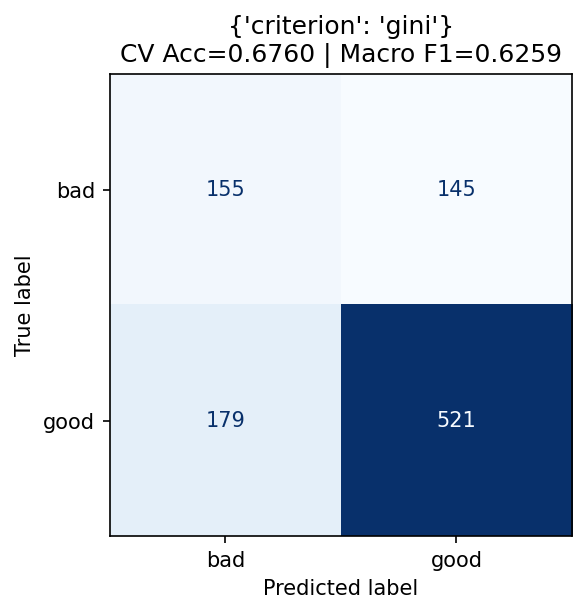

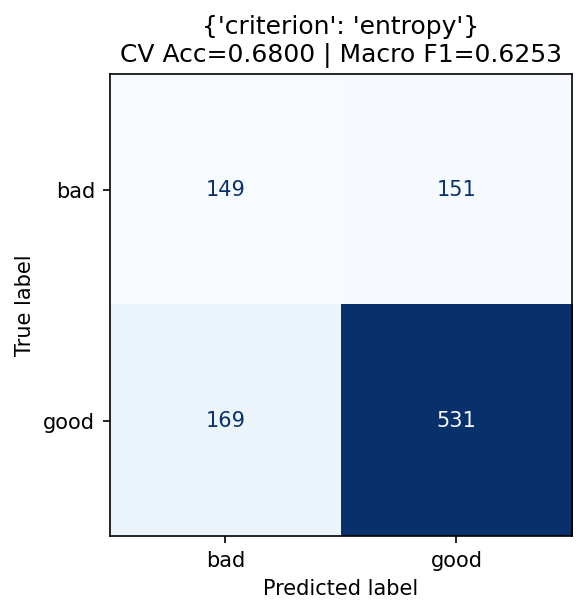

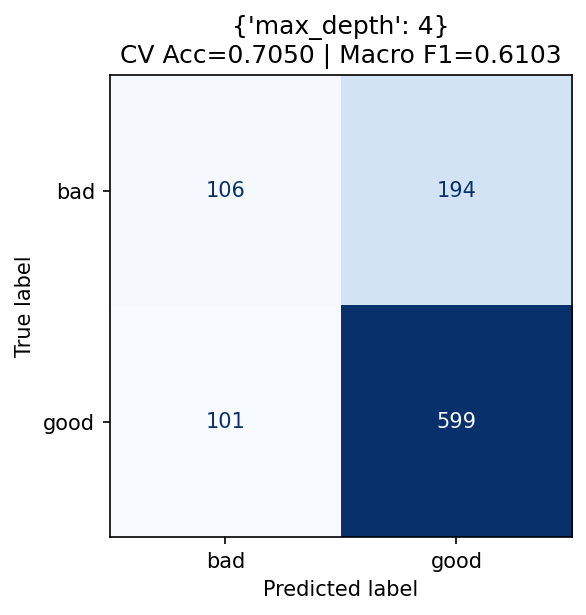

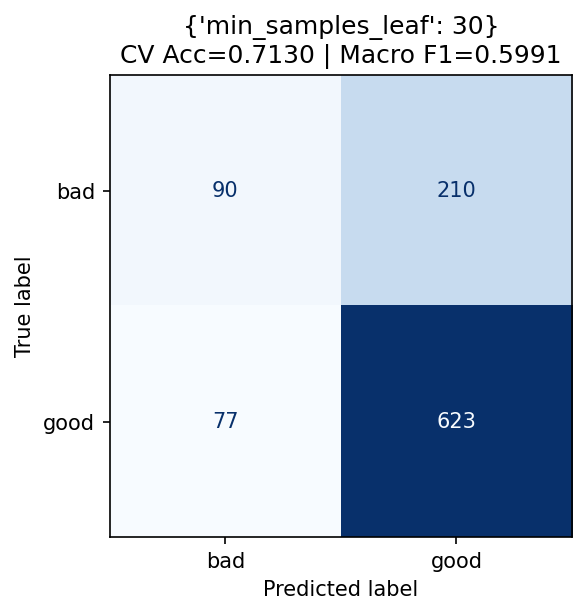

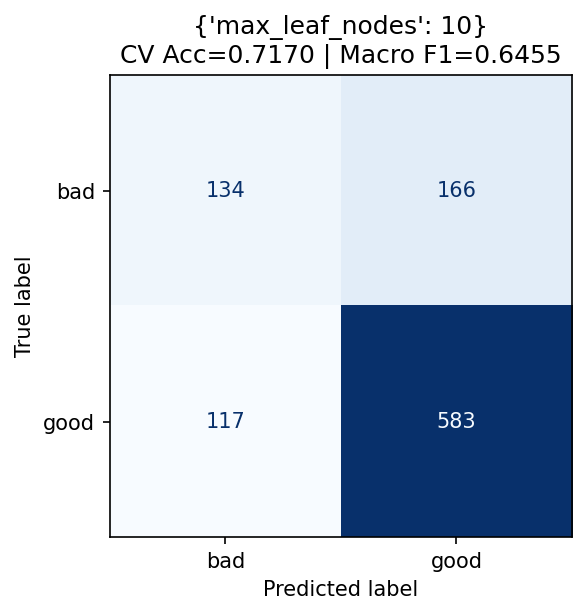

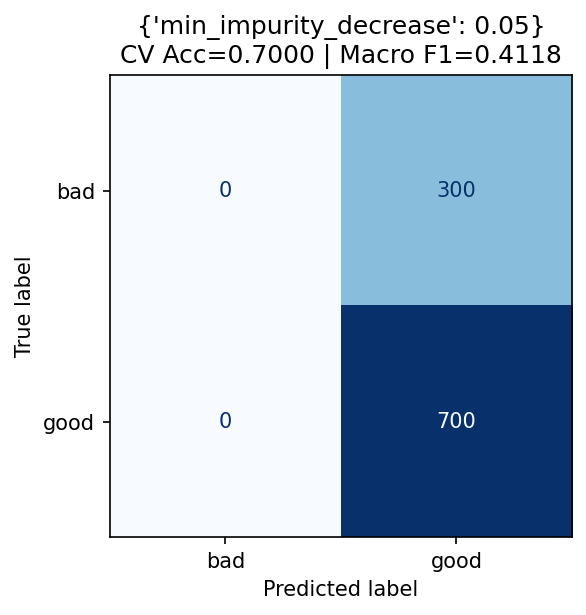

In [43]:
cm_configs = [
    {"criterion": "gini"},
    {"criterion": "entropy"},
    {"max_depth": 4},
    {"min_samples_leaf": 30},
    {"max_leaf_nodes": 10},
    {"min_impurity_decrease": 0.05},
]

for i, cfg in enumerate(cm_configs, 1):
    clf = DecisionTreeClassifier(random_state=42, **cfg)
    y_pred_cv = cross_val_predict(clf, X, y, cv=cv)
    cm = confusion_matrix(y, y_pred_cv, labels=clf.fit(X, y).classes_)
    
    fig, ax = plt.subplots(figsize=(5, 4), dpi=150)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{cfg}\nCV Acc={accuracy_score(y, y_pred_cv):.4f} | Macro F1={f1_score(y, y_pred_cv, average='macro'):.4f}")
    plt.savefig(f"./figs/cm_{i}.png")
    plt.show()

Passando alla 5-fold Stratified Cross-Validation, si osserva come una regolarizzazione moderata migliori la capacità di generalizzazione del modello rispetto agli alberi lasciati liberi di crescere:

- Impatto dei parametri su CV Accuracy e Macro F1:

    - Senza vincoli gini e entropy, l'accuracy scende drasticamente rispetto al training set (0.676 e 0.680), con un Macro F1 intorno a 0.625.

    - Limitando la complessità con valori intermedi — come max_leaf_nodes=10 (CV Accuracy 0.717, Macro F1 0.645), max_leaf_nodes=20 (CV Accuracy 0.713, Macro F10.649), min_samples_leaf=15 (CV Accuracy 0.707, Macro F1 0.638) o max_depth=4 (CV Accuracy 0.705, Macro F1 0.610) — il modello evita di adattarsi al rumore e raggiunge le prestazioni migliori su dati non visti.

    - Una potatura eccessiva (max_depth=2 o min_impurity_decreas >= 0.1)  peggiora invece il modello (underfitting), facendo scendere il Macro F1 perché la classe minoritaria 'bad' non viene più riconosciuta.

- Confronto Train vs CV Accuracy e Overfitting:

    - Le configurazioni non vincolate criterion='gini  o criterion='entropy' mostrano un forte overfitting, con un divario di circa 0.30 tra training accuracy (0.979) e CV accuracy (0.676–0.680).

- Classificatore banale :

    - Le configurazioni con min_impurity_decrease=0.02 e min_impurity_decrease=0.05 si comportano come classificatori banali: ottengono una CV accuracy esattamente pari a 0.700 che è la frequenza della classe maggioritaria 'good' e un Macro F1 di 0.411, che corrisponde a 0 veri positivi sulla classe 'bad'

4. Considerando il classificatore K-Nearest Neighbors (K-NN) ed eseguendo una Stratified Cross-Validation a 5 fold, quale impatto hanno il parametro K e lo schema di pesatura (uniform vs distance) sull'accuracy media e sul macro F1-score del classificatore? Riportare almeno 5 immagini delle matrici di confusione ottenute utilizzando diversi valori del parametro K.

    Successivamente, eseguire una Stratified Cross-Validation a 5 fold con due varianti di Naïve Bayes: Gaussian Naïve Bayes e Categorical Naïve Bayes. Quale variante è più adatta agli attributi del dataset Credit e perché? K-NN ottiene mediamente prestazioni migliori o peggiori rispetto a Naïve Bayes sui dati analizzati? La risposta cambia se si confronta il macro F1-score anziché l'accuracy? Allegare le immagini delle matrici di confusione dei classificatori Naïve Bayes prodotte dal proprio codice.

In [45]:
k_values = [1, 3, 5, 9, 15, 25, 41]
weights_list = ['uniform', 'distance']

results_knn = []

for w in weights_list:
    for k in k_values:
        # Pipeline con StandardScaler per evitare data leakage tra i fold
        knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights=w))
        y_pred_cv = cross_val_predict(knn, X, y, cv=cv)
        
        results_knn.append({
            "K": k,
            "Weights": w,
            "CV Accuracy": round(accuracy_score(y, y_pred_cv), 4),
            "Macro F1": round(f1_score(y, y_pred_cv, average='macro'), 4)
        })

df_knn = pd.DataFrame(results_knn)
df_knn

,K,Weights,CV Accuracy,Macro F1
0,1,uniform,0.659,0.5913
1,3,uniform,0.673,0.5857
2,5,uniform,0.690,0.5982
3,9,uniform,0.707,0.6001
4,15,uniform,0.732,0.6182
5,25,uniform,0.730,0.6079
6,41,uniform,0.744,0.6059
7,1,distance,0.659,0.5913
8,3,distance,0.680,0.6014
9,5,distance,0.687,0.6035


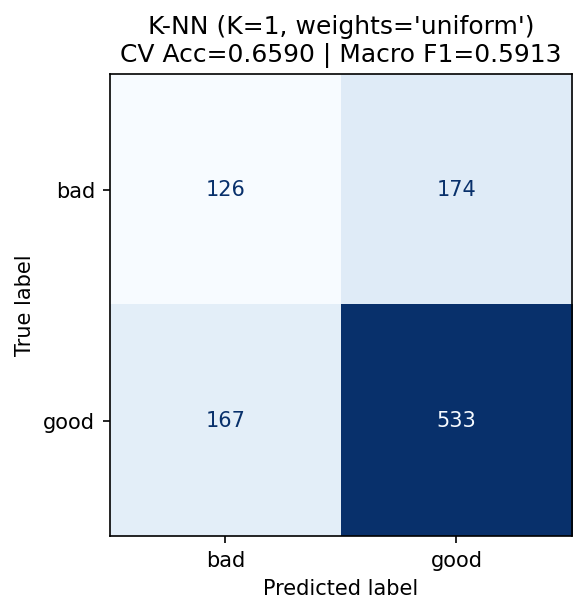

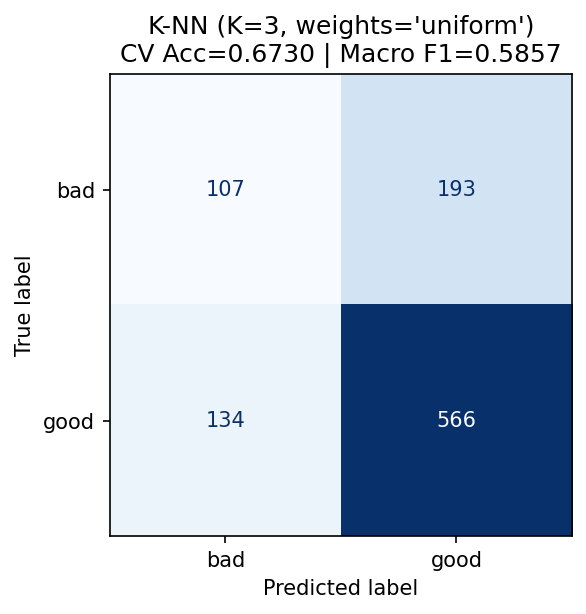

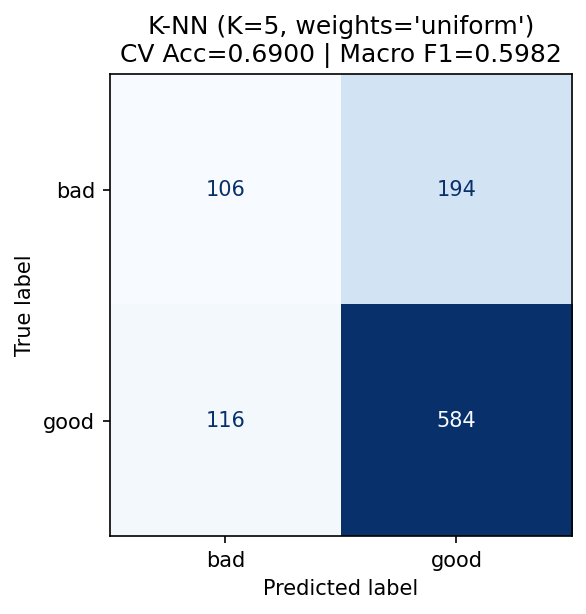

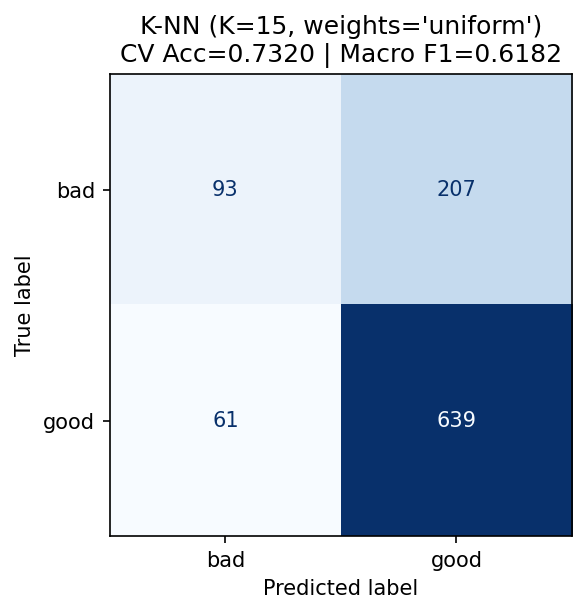

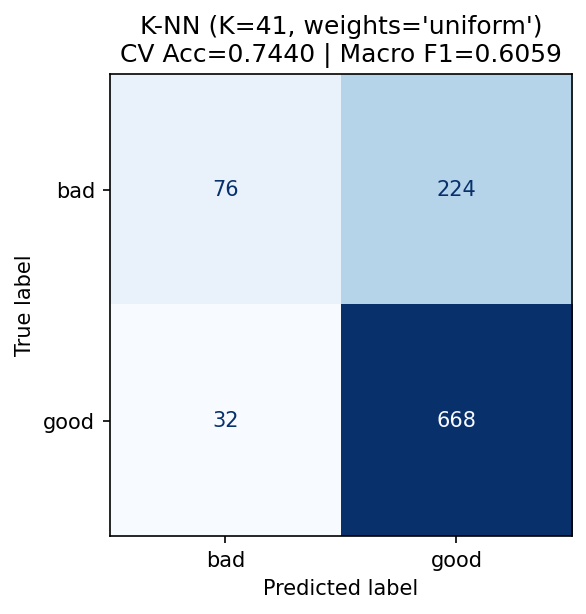

In [47]:
plot_k = [1, 3, 5, 15, 41]
class_labels = sorted(y.unique())

for i, k in enumerate(plot_k, 1):
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights='uniform'))
    y_pred_cv = cross_val_predict(knn, X, y, cv=cv)
    cm = confusion_matrix(y, y_pred_cv, labels=class_labels)
    
    fig, ax = plt.subplots(figsize=(5, 4), dpi=150)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"K-NN (K={k}, weights='uniform')\nCV Acc={accuracy_score(y, y_pred_cv):.4f} | Macro F1={f1_score(y, y_pred_cv, average='macro'):.4f}")
    plt.savefig(f"./figs/knn_cm_{i}.png")
    plt.show()

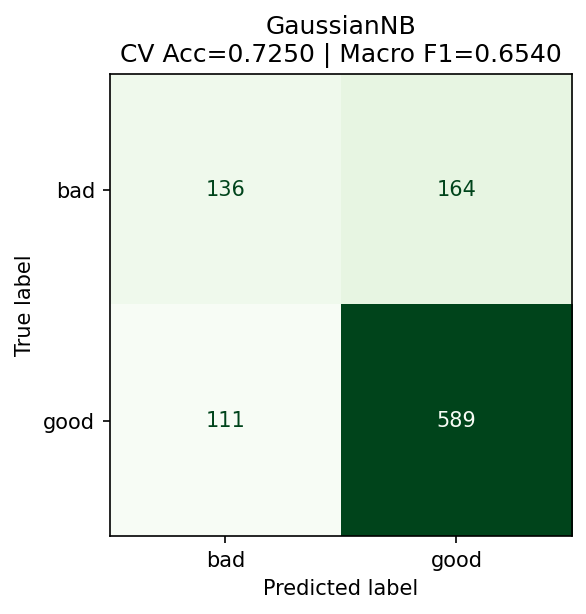

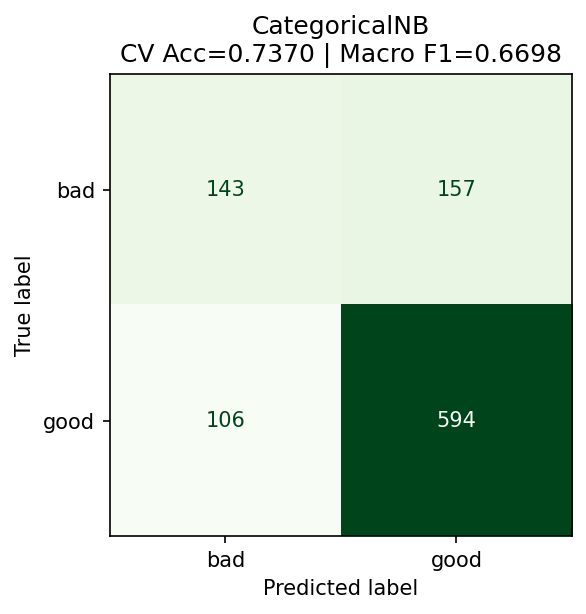

,Modello,CV Accuracy,Macro F1
0,GaussianNB,0.725,0.6540
1,CategoricalNB,0.737,0.6698


In [49]:
nb_models = {
    "GaussianNB": GaussianNB(),
    "CategoricalNB": CategoricalNB(min_categories=X.nunique().values)
}

results_nb = []

for name, model in nb_models.items():
    y_pred_cv = cross_val_predict(model, X, y, cv=cv)
    acc = accuracy_score(y, y_pred_cv)
    macro_f1 = f1_score(y, y_pred_cv, average='macro')
    
    results_nb.append({
        "Modello": name,
        "CV Accuracy": round(acc, 4),
        "Macro F1": round(macro_f1, 4)
    })
    
    # Plot della matrice di confusione
    cm = confusion_matrix(y, y_pred_cv, labels=class_labels)
    fig, ax = plt.subplots(figsize=(5, 4), dpi=150)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=ax, cmap="Greens", colorbar=False)
    ax.set_title(f"{name}\nCV Acc={acc:.4f} | Macro F1={macro_f1:.4f}")
    plt.savefig(f"./figs/nb_{name}.png", bbox_inches="tight")
    plt.show()

df_nb = pd.DataFrame(results_nb)
df_nb

Impatto di K e dello schema di pesatura su K-NN:

- Valore di K: con valori piccoli (K=1, 3, 5), il classificatore risente del rumore locale (overfitting) e ottiene una CV accuracy bassa 0.659–0.690 e un Macro F1 intorno a 0.586–0.604. Aumentando K fino a valori intermedi (K=15), il modello regolarizza i confini decisionali e migliora sia l'accuracy, 0.732 con uniform, 0.727 con distance, sia il Macro F1 che raggiunge il massimo di 0.6182 con uniform e 0.627 con distance. Per K$molto elevati (K=41), l'accuracy sale ulteriormente fino a 0.744 con uniform, ma il Macro F1 scende a 0.605. 

- Schema di pesatura: con K piccoli o intermedi (K=3, 9, 15), weights='distance' migliora leggermente il Macro F1, si passa da 0.618 a 0.627 per K=15,  dando più peso ai vicini più prossimi; per K grandi (K=25, 41), weights='uniform' mantiene un'accuracy leggermente superiore, 0.744 contro 0.728 a K=41, perché attenua l'influenza di singoli punti rumorosi molto vicini.

Confronto tra Gaussian e Categorical Naïve Bayes

- CategoricalNB ottiene risultati superiori rispetto a GaussianNB sia per CV accuracy, 0.737 contro 0.725,  sia per Macro F1, 0.6698 contro 0.6540. Questo perché: nel dataset utilizzato tutti gli attributi  sono categorici o ordinali finiti codificati con LabelEncoder. CategoricalNB stima direttamente le probabilità categoriche per ciascuna modalità, mentre GaussianNB assume una distribuzione normale continua e un ordinamento metrico arbitrario introdotto dai codici numerici del LabelEncoder.

Confronto K-NN vs Naïve Bayes (Accuracy vs Macro F1-score):

- Guardando all'accuracy: K-NN con K grande (K=41, uniform : 0.744) supera leggermente CategoricalNB (0.737) e GaussianNB (0.725), mentre per K piccoli/medi Naïve Bayes è mediamente superiore.

- Guardando al Macro F1-score la risposta cambia nettamente: entrambi i modelli Naïve Bayes  superano ampiamente la miglior configurazione di K-NN.

5. Analizzare la matrice di correlazione (Correlation Matrix), includendo l'attributo di classe, per individuare le correlazioni tra coppie di attributi del dataset. Allegare l'immagine della matrice di correlazione (heatmap) prodotta dal proprio codice.

    a) L'ipotesi di indipendenza alla base di Naïve Bayes è effettivamente soddisfatta per il dataset Credit? 

    b)Qual è la coppia di attributi maggiormente correlati?

    c) Quale attributo presenta la correlazione più elevata con la classe? È lo stesso attributo selezionato come radice dell'albero decisionale nella Domanda 1? Discutere perché i due attributi potrebbero essere differenti.

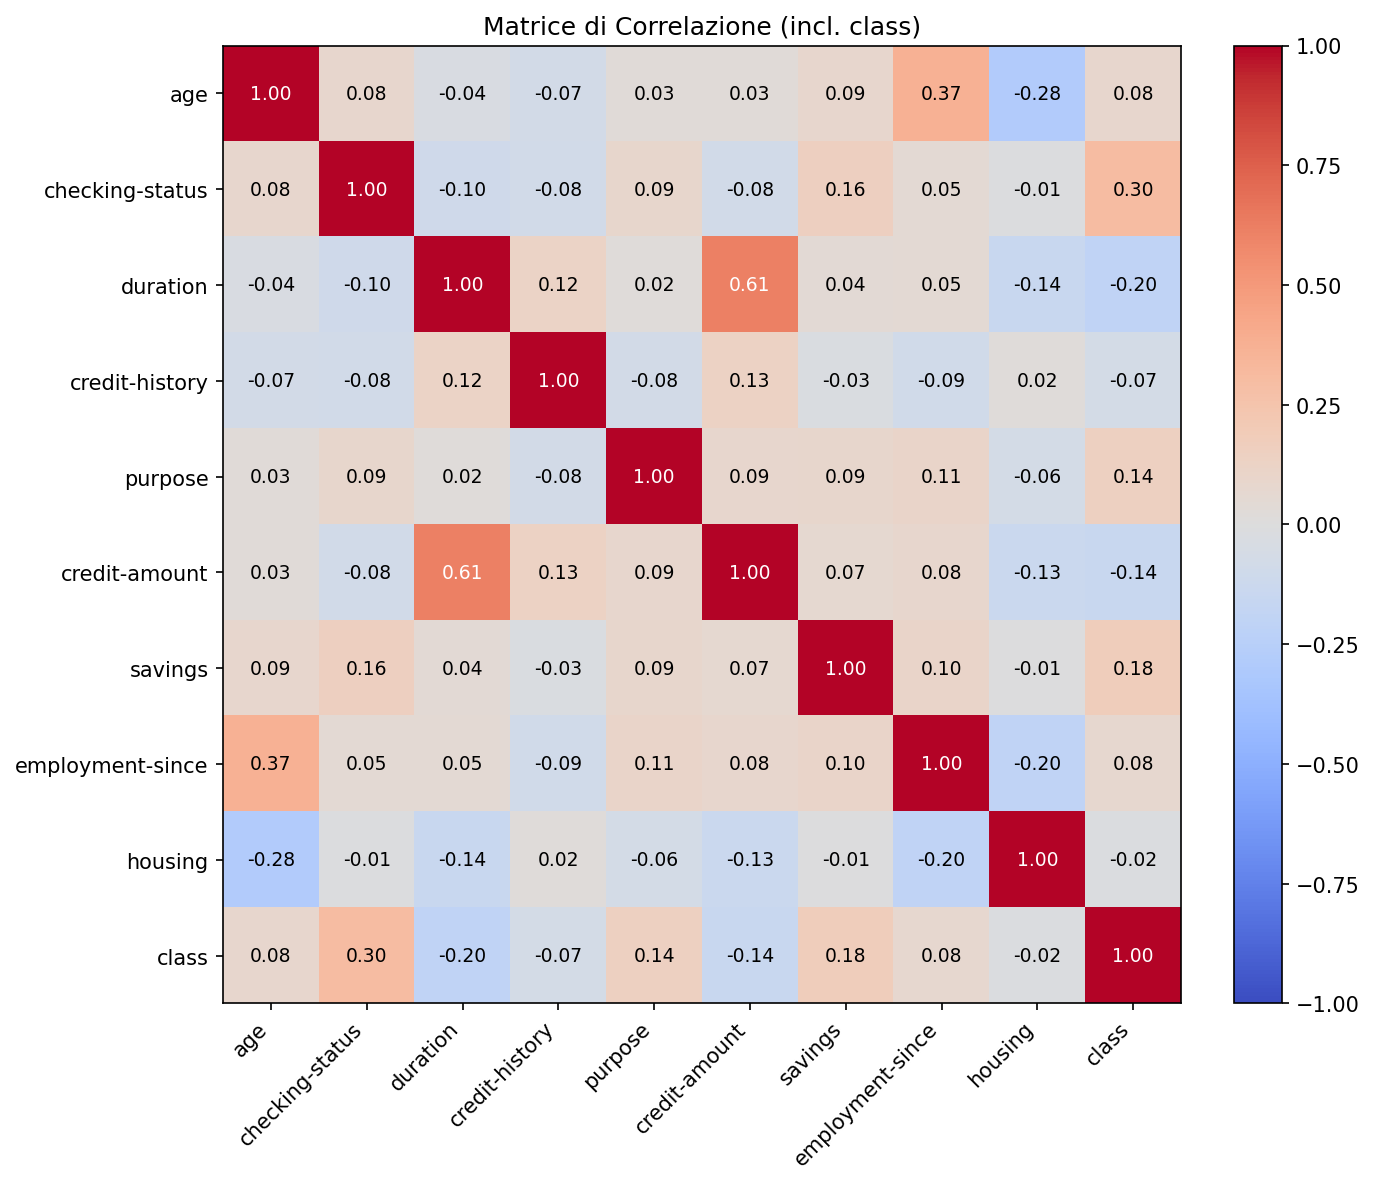

In [50]:
# 1. Creazione del DataFrame completo includendo la classe codificata
df_corr = X.copy()
le_y = LabelEncoder()
df_corr['class'] = le_y.fit_transform(y)

# Calcolo della matrice di correlazione di Pearson
corr_matrix = df_corr.corr()

# 2. Plot della heatmap
fig, ax = plt.subplots(figsize=(10, 8), dpi=150)
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Etichette sugli assi
cols = corr_matrix.columns
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right')
ax.set_yticklabels(cols)

# Scrittura dei valori numerici in ogni cella
for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr_matrix.iloc[i, j]
        color = "white" if abs(val) > 0.5 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=9)

ax.set_title("Matrice di Correlazione (incl. class)")
plt.tight_layout()
plt.savefig("./figs/correlation_matrix.png")
plt.show()

In [52]:
# Coppia di attributi (esclusa la classe) con correlazione massima in valore assoluto
feat_corr = corr_matrix.drop(index='class', columns='class').abs()
np.fill_diagonal(feat_corr.values, 0)
max_pair = feat_corr.unstack().idxmax()
max_val = corr_matrix.loc[max_pair[0], max_pair[1]]
print(f"Coppia più correlata: {max_pair[0]} e {max_pair[1]} (r = {max_val:.4f})")

# Correlazione degli attributi con la classe (ordinati per valore assoluto)
class_corr = corr_matrix['class'].drop('class')
print("\nCorrelazione con la classe (ordinata per |r|):")
print(class_corr.reindex(class_corr.abs().sort_values(ascending=False).index))

Coppia più correlata: duration e credit-amount (r = 0.6132)

Correlazione con la classe (ordinata per |r|):
checking-status     0.302406
duration           -0.198079
savings             0.178943
purpose             0.142693
credit-amount      -0.142372
age                 0.083026
employment-since    0.076891
credit-history     -0.065076
housing            -0.019315
Name: class, dtype: float64


a) No, l'ipotesi di indipendenza condizionale tra gli attributi non è strettamente soddisfatta per il dataset Credit. Nella matrice di correlazione emergono infatti diverse correlazioni non trascurabili tra le feature (come duration e credit-amount con r = 0.613, oltre a legami tra age, housing ed employment-since). Nonostante questa violazione teorica, Naive Bayes riesce comunque a ottenere ottime prestazioni classificatorie.

b) La coppia di attributi più fortemente correlata è  duration e credit-amount  con un coefficiente di correlazione di Pearson pari a r = 0.613

c) L'attributo con la correlazione più elevata con Class è checking-status (r=0.302), che coincide con l'attributo selezionato come nodo radice dell'albero decisionale nella